<a href="https://colab.research.google.com/github/mayank-aroradev/customer_churn/blob/main/churned.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [94]:
import kagglehub
path = kagglehub.dataset_download("olistbr/brazilian-ecommerce")
print(path)

Using Colab cache for faster access to the 'brazilian-ecommerce' dataset.
/kaggle/input/brazilian-ecommerce


In [95]:
import pandas as pd, os

files = os.listdir(path)
print(files)

customers = pd.read_csv(f"{path}/olist_customers_dataset.csv")
orders    = pd.read_csv(f"{path}/olist_orders_dataset.csv",
                        parse_dates=["order_purchase_timestamp"])
items     = pd.read_csv(f"{path}/olist_order_items_dataset.csv")
payments  = pd.read_csv(f"{path}/olist_order_payments_dataset.csv")
reviews   = pd.read_csv(f"{path}/olist_order_reviews_dataset.csv")
products  = pd.read_csv(f"{path}/olist_products_dataset.csv")

['olist_customers_dataset.csv', 'olist_sellers_dataset.csv', 'olist_order_reviews_dataset.csv', 'olist_order_items_dataset.csv', 'olist_products_dataset.csv', 'olist_geolocation_dataset.csv', 'product_category_name_translation.csv', 'olist_orders_dataset.csv', 'olist_order_payments_dataset.csv']


In [96]:
customers.head()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


In [97]:
orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [98]:
items

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14
...,...,...,...,...,...,...,...
112645,fffc94f6ce00a00581880bf54a75a037,1,4aa6014eceb682077f9dc4bffebc05b0,b8bc237ba3788b23da09c0f1f3a3288c,2018-05-02 04:11:01,299.99,43.41
112646,fffcd46ef2263f404302a634eb57f7eb,1,32e07fd915822b0765e448c4dd74c828,f3c38ab652836d21de61fb8314b69182,2018-07-20 04:31:48,350.00,36.53
112647,fffce4705a9662cd70adb13d4a31832d,1,72a30483855e2eafc67aee5dc2560482,c3cfdc648177fdbbbb35635a37472c53,2017-10-30 17:14:25,99.90,16.95
112648,fffe18544ffabc95dfada21779c9644f,1,9c422a519119dcad7575db5af1ba540e,2b3e4a2a3ea8e01938cabda2a3e5cc79,2017-08-21 00:04:32,55.99,8.72


In [99]:
reviews.head()

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53


In [100]:
customers.customer_unique_id.unique()

array(['861eff4711a542e4b93843c6dd7febb0',
       '290c77bc529b7ac935b93aa66c333dc3',
       '060e732b5b29e8181a18229c7b0b2b5e', ...,
       'e9f50caf99f032f0bf3c55141f019d99',
       '73c2643a0a458b49f58cea58833b192e',
       '84732c5050c01db9b23e19ba39899398'], dtype=object)

In [101]:
import pandas as pd

# 1. Merge orders with customers to map each order to its customer_unique_id
customer_orders = pd.merge(orders, customers, on='customer_id', how='inner')

# 2. Count the number of unique orders per unique customer
purchases_per_customer = customer_orders.groupby('customer_unique_id')['order_id'].nunique().reset_index()
purchases_per_customer.rename(columns={'order_id': 'purchase_count'}, inplace=True)

# 3. Classify customers into 'Bought Once' vs 'Bought Multiple Times'
def categorize_purchases(count):
    return 'Bought Once' if count == 1 else 'Bought Multiple Times'

purchases_per_customer['category'] = purchases_per_customer['purchase_count'].apply(categorize_purchases)

# 4. Count the number of customers in each category and calculate percentages
summary = purchases_per_customer['category'].value_counts().reset_index()
summary.columns = ['Category', 'Number of Customers']
summary['Percentage (%)'] = (summary['Number of Customers'] / summary['Number of Customers'].sum() * 100).round(2)

display(summary)

# Also display exact frequency distribution of purchase counts
print("\nDetailed breakdown of purchase frequencies:")
print(purchases_per_customer['purchase_count'].value_counts().sort_index().to_frame('Number of Customers'))

,Category,Number of Customers,Percentage (%)
0,Bought Once,93099,96.88
1,Bought Multiple Times,2997,3.12



Detailed breakdown of purchase frequencies:
                Number of Customers
purchase_count                     
1                             93099
2                              2745
3                               203
4                                30
5                                 8
6                                 6
7                                 3
9                                 1
17                                1


In [102]:
customer_orders

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,7c396fd4830fd04220f754e42b4e5bff,3149,sao paulo,SP
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00,af07308b275d755c9edb36a90c618231,47813,barreiras,BA
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00,3a653a41f6f9fc3d2a113cf8398680e8,75265,vianopolis,GO
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00,7c142cf63193a1473d2e66489a9ae977,59296,sao goncalo do amarante,RN
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00,72632f0f9dd73dfee390c9b22eb56dd6,9195,santo andre,SP
...,...,...,...,...,...,...,...,...,...,...,...,...
99436,9c5dedf39a927c1b2549525ed64a053c,39bd1228ee8140590ac3aca26f2dfe00,delivered,2017-03-09 09:54:05,2017-03-09 09:54:05,2017-03-10 11:18:03,2017-03-17 15:08:01,2017-03-28 00:00:00,6359f309b166b0196dbf7ad2ac62bb5a,12209,sao jose dos campos,SP
99437,63943bddc261676b46f01ca7ac2f7bd8,1fca14ff2861355f6e5f14306ff977a7,delivered,2018-02-06 12:58:58,2018-02-06 13:10:37,2018-02-07 23:22:42,2018-02-28 17:37:56,2018-03-02 00:00:00,da62f9e57a76d978d02ab5362c509660,11722,praia grande,SP
99438,83c1379a015df1e13d02aae0204711ab,1aa71eb042121263aafbe80c1b562c9c,delivered,2017-08-27 14:46:43,2017-08-27 15:04:16,2017-08-28 20:52:26,2017-09-21 11:24:17,2017-09-27 00:00:00,737520a9aad80b3fbbdad19b66b37b30,45920,nova vicosa,BA
99439,11c177c8e97725db2631073c19f07b62,b331b74b18dc79bcdf6532d51e1637c1,delivered,2018-01-08 21:28:27,2018-01-08 21:36:21,2018-01-12 15:35:03,2018-01-25 23:32:54,2018-02-15 00:00:00,5097a5312c8b157bb7be58ae360ef43c,28685,japuiba,RJ


In [103]:
import pandas as pd

# 1. Identify loyal customers (those who have ordered more than once)
# We can reuse our purchases_per_customer DataFrame or compute it here
loyal_customers = purchases_per_customer[purchases_per_customer['purchase_count'] > 1]

# 2. Filter reviews for scores strictly above 4 (which is score = 5)
high_reviews = reviews[reviews['review_score'] > 4]

# 3. Join reviews with customer orders to link reviews back to customer_unique_id
# First, merge reviews with orders on order_id
order_reviews = pd.merge(high_reviews, orders, on='order_id', how='inner')
# Then merge with customers to get customer_unique_id
customer_high_reviews = pd.merge(order_reviews, customers, on='customer_id', how='inner')

# 4. Filter for customers who are in the loyal customer list (reordered)
loyal_high_reviewers = customer_high_reviews[customer_high_reviews['customer_unique_id'].isin(loyal_customers['customer_unique_id'])]

# Display unique customers who match both criteria
unique_loyal_high_reviewers = loyal_high_reviewers[['customer_unique_id']].drop_duplicates()

print(f"Total unique customers who reordered and gave a review score > 2: {len(unique_loyal_high_reviewers)}")
display(unique_loyal_high_reviewers.head())

Total unique customers who reordered and gave a review score > 2: 2186


,customer_unique_id
17,d277ef4a75c805239e54be86625e0722
18,21effa61d72771ba8315ab56ce7fb7ac
32,b918da4934c7eabcda6e45b4e18aba53
36,97f0fce3f9d7aad1b12499a4e4b10d07
49,b7474898d0dccad79a77bf2b0d23bbab


In [104]:
# Merge all primary tables to create a master consolidated DataFrame

# 1. Start with order items
merged_df = pd.merge(items, orders, on='order_id', how='left')

# 2. Merge with customers
merged_df = pd.merge(merged_df, customers, on='customer_id', how='left')

# 3. Merge with payments
merged_df = pd.merge(merged_df, payments, on='order_id', how='left')

# 4. Merge with reviews
merged_df = pd.merge(merged_df, reviews, on='order_id', how='left')

# 5. Merge with products
merged_df = pd.merge(merged_df, products, on='product_id', how='left')

print(f"Consolidated DataFrame shape: {merged_df.shape}")
display(merged_df.head())

Consolidated DataFrame shape: (118310, 36)


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,customer_id,order_status,order_purchase_timestamp,...,review_creation_date,review_answer_timestamp,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,3ce436f183e68e07877b285a838db11a,delivered,2017-09-13 08:59:02,...,2017-09-21 00:00:00,2017-09-22 10:57:03,cool_stuff,58.0,598.0,4.0,650.0,28.0,9.0,14.0
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,f6dd3ec061db4e3987629fe6b26e5cce,delivered,2017-04-26 10:53:06,...,2017-05-13 00:00:00,2017-05-15 11:34:13,pet_shop,56.0,239.0,2.0,30000.0,50.0,30.0,40.0
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,6489ae5e4333f3693df5ad4372dab6d3,delivered,2018-01-14 14:33:31,...,2018-01-23 00:00:00,2018-01-23 16:06:31,moveis_decoracao,59.0,695.0,2.0,3050.0,33.0,13.0,33.0
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,d4eb9395c8c0431ee92fce09860c5a06,delivered,2018-08-08 10:00:35,...,2018-08-15 00:00:00,2018-08-15 16:39:01,perfumaria,42.0,480.0,1.0,200.0,16.0,10.0,15.0
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,58dbd0b2d70206bf40e62cd34e84d795,delivered,2017-02-04 13:57:51,...,2017-03-02 00:00:00,2017-03-03 10:54:59,ferramentas_jardim,59.0,409.0,1.0,3750.0,35.0,40.0,30.0


In [105]:
# 1. Count the number of unique orders per unique customer
customer_order_counts = merged_df.groupby('customer_unique_id')['order_id'].nunique()

# 2. Map this count back to merged_df using customer_unique_id
merged_df['total_customer_orders'] = merged_df['customer_unique_id'].map(customer_order_counts)

# 3. Classify whether the customer has reordered: 0 for single order, 1 for > 1 orders
merged_df['reordered'] = (merged_df['total_customer_orders'] > 1).astype(int)

# Display the unique value distribution and a preview of the columns
print("Reordered classification distribution (0 = Single Order, 1 = Reordered):")
print(merged_df['reordered'].value_counts())

display(merged_df[['customer_unique_id', 'order_id', 'total_customer_orders', 'reordered']].head(10))

Reordered classification distribution (0 = Single Order, 1 = Reordered):
reordered
0    109792
1      8518
Name: count, dtype: int64


,customer_unique_id,order_id,total_customer_orders,reordered
0,871766c5855e863f6eccc05f988b23cb,00010242fe8c5a6d1ba2dd792cb16214,1,0
1,eb28e67c4c0b83846050ddfb8a35d051,00018f77f2f0320c557190d7a144bdd3,2,1
2,3818d81c6709e39d06b2738a8d3a2474,000229ec398224ef6ca0657da4fc703e,1,0
3,af861d436cfc08b2c2ddefd0ba074622,00024acbcdf0a6daa1e931b038114c75,1,0
4,64b576fb70d441e8f1b2d7d446e483c5,00042b26cf59d7ce69dfabb4e55b4fd9,1,0
5,85c835d128beae5b4ce8602c491bf385,00048cc3ae777c65dbb7d2a0634bc1ea,1,0
6,635d9ac1680f03288e72ada3a1035803,00054e8431b9d7675808bcb819fb4a32,1,0
7,fda4476abb6307ab3c415b7e6d026526,000576fe39319847cbb9d288c5617fa6,1,0
8,639d23421f5517f69d0c3d6e6564cf0e,0005a1a1728c9d785b8e2b08b904576c,1,0
9,0782c41380992a5a533489063df0eef6,0005f50442cb953dcd1d21e1fb923495,1,0


In [106]:
purchases_per_customer['purchase_count'].value_counts()


,count
purchase_count,
1,93099
2,2745
3,203
4,30
5,8
6,6
7,3
9,1
17,1


In [107]:
purchases_per_customer

,customer_unique_id,purchase_count,category
0,0000366f3b9a7992bf8c76cfdf3221e2,1,Bought Once
1,0000b849f77a49e4a4ce2b2a4ca5be3f,1,Bought Once
2,0000f46a3911fa3c0805444483337064,1,Bought Once
3,0000f6ccb0745a6a4b88665a16c9f078,1,Bought Once
4,0004aac84e0df4da2b147fca70cf8255,1,Bought Once
...,...,...,...
96091,fffcf5a5ff07b0908bd4e2dbc735a684,1,Bought Once
96092,fffea47cd6d3cc0a88bd621562a9d061,1,Bought Once
96093,ffff371b4d645b6ecea244b27531430a,1,Bought Once
96094,ffff5962728ec6157033ef9805bacc48,1,Bought Once


In [108]:
# Use parenthesized conditions and the '&' operator for element-wise logical AND
filtered_df = merged_df[(merged_df['price'] > 100) & (merged_df['review_score'] > 4)]
filtered_df.shape

(23792, 38)

In [109]:
merged_df['product_category_name'].value_counts()

,count
product_category_name,
cama_mesa_banho,11988
beleza_saude,10032
esporte_lazer,9004
moveis_decoracao,8832
informatica_acessorios,8150
...,...
portateis_cozinha_e_preparadores_de_alimentos,15
cds_dvds_musicais,14
pc_gamer,10


In [110]:
# Ensure the temporary mapping column is calculated
customer_order_counts = merged_df.groupby('customer_unique_id')['order_id'].nunique()
merged_df['total_customer_orders'] = merged_df['customer_unique_id'].map(customer_order_counts)

# Map total customer orders to a binary column: 0 for single order, 1 for reordered
merged_df['reordered'] = (merged_df['total_customer_orders'] > 1).astype(int)

# Display the unique value distribution to verify
print(merged_df['reordered'].value_counts())
display(merged_df[['customer_unique_id', 'order_id', 'total_customer_orders', 'reordered']].head(10))

reordered
0    109792
1      8518
Name: count, dtype: int64


,customer_unique_id,order_id,total_customer_orders,reordered
0,871766c5855e863f6eccc05f988b23cb,00010242fe8c5a6d1ba2dd792cb16214,1,0
1,eb28e67c4c0b83846050ddfb8a35d051,00018f77f2f0320c557190d7a144bdd3,2,1
2,3818d81c6709e39d06b2738a8d3a2474,000229ec398224ef6ca0657da4fc703e,1,0
3,af861d436cfc08b2c2ddefd0ba074622,00024acbcdf0a6daa1e931b038114c75,1,0
4,64b576fb70d441e8f1b2d7d446e483c5,00042b26cf59d7ce69dfabb4e55b4fd9,1,0
5,85c835d128beae5b4ce8602c491bf385,00048cc3ae777c65dbb7d2a0634bc1ea,1,0
6,635d9ac1680f03288e72ada3a1035803,00054e8431b9d7675808bcb819fb4a32,1,0
7,fda4476abb6307ab3c415b7e6d026526,000576fe39319847cbb9d288c5617fa6,1,0
8,639d23421f5517f69d0c3d6e6564cf0e,0005a1a1728c9d785b8e2b08b904576c,1,0
9,0782c41380992a5a533489063df0eef6,0005f50442cb953dcd1d21e1fb923495,1,0


In [111]:
work_df=merged_df
work_df.shape
work_df['reordered'].value_counts()

,count
reordered,
0,109792
1,8518


In [112]:
work_df.drop_duplicates(inplace=True)

In [113]:
work_df.describe()

,order_item_id,price,freight_value,order_purchase_timestamp,customer_zip_code_prefix,payment_sequential,payment_installments,payment_value,review_score,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,total_customer_orders,reordered
count,118310.000000,118310.000000,118310.000000,118310,118310.000000,118307.000000,118307.000000,118307.000000,117332.000000,116601.000000,116601.000000,116601.000000,118290.000000,118290.000000,118290.000000,118290.000000,118310.000000,118310.000000
mean,1.196543,120.646603,20.032387,2017-12-30 06:31:38.646944768,35050.658693,1.094069,2.943317,172.575102,4.031390,48.767498,785.967822,2.205161,2112.250740,30.265145,16.619706,23.074799,1.089147,0.071997
min,1.000000,0.850000,0.000000,2016-09-04 21:15:19,1003.000000,1.000000,0.000000,0.000000,1.000000,5.000000,4.000000,1.000000,0.000000,7.000000,2.000000,6.000000,1.000000,0.000000
25%,1.000000,39.900000,13.080000,2017-09-11 15:08:33.750000128,11310.000000,1.000000,1.000000,60.850000,4.000000,42.000000,346.000000,1.000000,300.000000,18.000000,8.000000,15.000000,1.000000,0.000000
50%,1.000000,74.900000,16.280000,2018-01-17 22:38:25.500000,24275.500000,1.000000,2.000000,108.200000,5.000000,52.000000,600.000000,1.000000,700.000000,25.000000,13.000000,20.000000,1.000000,0.000000
75%,1.000000,134.900000,21.180000,2018-05-03 16:34:57,58636.250000,1.000000,4.000000,189.260000,5.000000,57.000000,983.000000,3.000000,1800.000000,38.000000,20.000000,30.000000,1.000000,0.000000
max,21.000000,6735.000000,409.680000,2018-09-03 09:06:57,99990.000000,29.000000,24.000000,13664.080000,5.000000,76.000000,3992.000000,20.000000,40425.000000,105.000000,105.000000,118.000000,16.000000,1.000000
std,0.699489,184.109691,15.836850,NaN,29824.585904,0.728579,2.777877,267.110727,1.387994,10.033540,652.584121,1.717452,3786.695111,16.189367,13.453584,11.749139,0.400457,0.258485


In [114]:
mino=work_df[work_df['reordered']==0]
majo=work_df[work_df['reordered']==1]
majo_work=majo.sample(n=8000,random_state=42)
mino_work=mino.sample(n=8000,random_state=42)
workequal=pd.concat([majo_work,mino_work])

In [115]:
workequal=workequal.sample(frac=1,random_state=42).reset_index(drop=True)

In [116]:
workequal['reordered'].value_counts()

,count
reordered,
0,8000
1,8000


In [117]:
workequal.isnull().sum()

,0
order_id,0
order_item_id,0
product_id,0
seller_id,0
shipping_limit_date,0
price,0
freight_value,0
customer_id,0
order_status,0
order_purchase_timestamp,0


In [118]:
workequal.dropna(inplace=True)

In [119]:
workequal.isnull().sum()

,0
order_id,0
order_item_id,0
product_id,0
seller_id,0
shipping_limit_date,0
price,0
freight_value,0
customer_id,0
order_status,0
order_purchase_timestamp,0


In [120]:
workequal.shape

(1393, 38)

In [121]:
import pandas as pd
import numpy as np

# Let's re-create 'workequal' from the sample to start fresh before dropping occurred
mino = work_df[work_df['reordered'] == 0]
majo = work_df[work_df['reordered'] == 1]
majo_work = majo.sample(n=8000, random_state=42, replace=True) # Using replace=True to handle small sample sizes safely
mino_work = mino.sample(n=8000, random_state=42, replace=True)
workequal = pd.concat([majo_work, mino_work])
workequal = workequal.sample(frac=1, random_state=42).reset_index(drop=True)

# Fill missing values based on column type and meaning
fill_values = {
    # Review Text & Titles
    'review_id': 'No Review',
    'review_score': 0, # Or standard neutral/average score like 3
    'review_comment_title': 'No Title',
    'review_comment_message': 'No Message',
    'review_creation_date': 'Unknown',
    'review_answer_timestamp': 'Unknown',

    # Order Timestamps (For missing approvals or deliveries, we'll mark as 'Not Applicable' or 'Unknown')
    'order_approved_at': 'Not Approved',
    'order_delivered_carrier_date': 'Not Shipped',
    'order_delivered_customer_date': 'Not Delivered',

    # Product specifications
    'product_category_name': 'unknown',
    'product_name_lenght': 0,
    'product_description_lenght': 0,
    'product_photos_qty': 0,
    'product_weight_g': 0,
    'product_length_cm': 0,
    'product_height_cm': 0,
    'product_width_cm': 0
}

workequal.fillna(value=fill_values, inplace=True)

# Verify null counts and new shape
print("Null counts after appropriate filling:")
print(workequal.isnull().sum())
print(f"\nNew shape of dataset: {workequal.shape}")
display(workequal.head())

Null counts after appropriate filling:
order_id                         0
order_item_id                    0
product_id                       0
seller_id                        0
shipping_limit_date              0
price                            0
freight_value                    0
customer_id                      0
order_status                     0
order_purchase_timestamp         0
order_approved_at                0
order_delivered_carrier_date     0
order_delivered_customer_date    0
order_estimated_delivery_date    0
customer_unique_id               0
customer_zip_code_prefix         0
customer_city                    0
customer_state                   0
payment_sequential               0
payment_type                     0
payment_installments             0
payment_value                    0
review_id                        0
review_score                     0
review_comment_title             0
review_comment_message           0
review_creation_date             0
review_answer_ti

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,customer_id,order_status,order_purchase_timestamp,...,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,total_customer_orders,reordered
0,8067c5e4834f3c0a3c8a4e921d65c5b1,2,dbb67791e405873b259e4656bf971246,6973a06f484aacf400ece213dbf3d946,2018-01-31 16:39:42,81.99,8.32,d06d665f5cbc5c4d6d32b95e3366753a,delivered,2018-01-24 16:28:22,...,informatica_acessorios,32.0,321.0,1.0,207.0,17.0,12.0,13.0,1,0
1,edd96b4f322cd7181741044d2e016158,1,9d0aa87e8df1bdbe0f79353520a2d538,0bae85eb84b9fb3bd773911e89288d54,2018-05-10 18:53:46,36.23,9.44,836760dcb82c039d393284e02bf6d7c3,delivered,2018-05-05 18:28:19,...,papelaria,54.0,111.0,3.0,550.0,28.0,12.0,12.0,2,1
2,516ddf29a9e99c8997f914e6b389cd19,1,4cb4ef491872bfc6e910b343d46c6325,0ea22c1cfbdc755f86b9b54b39c16043,2017-03-29 23:50:18,34.90,14.52,e9932a09e352ca9e469f31522a8466f0,shipped,2017-03-23 23:44:58,...,fashion_bolsas_e_acessorios,40.0,360.0,5.0,150.0,16.0,9.0,11.0,2,1
3,a9db785c3c219acb88a8a8c594045493,3,830102bc96abe72181372676df005601,3b15288545f8928d3e65a8f949a28291,2018-02-20 18:15:27,159.99,16.75,9e24614d3c9138935bdd12b9b0504a7a,delivered,2018-02-12 19:22:50,...,cama_mesa_banho,54.0,411.0,1.0,2250.0,42.0,16.0,36.0,2,1
4,765917871914309e5c5f9ed151155ad4,1,aa8d88eb4b9cb38894e33fa624c4287f,6560211a19b47992c3666cc44a7e94c0,2018-03-02 11:31:11,55.00,7.78,704e2db282206eaf28d686a1482fb224,canceled,2018-02-26 11:04:23,...,relogios_presentes,54.0,335.0,4.0,250.0,16.0,2.0,11.0,1,0


In [122]:
workequal.shape

(16000, 38)

In [123]:
workequal

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,customer_id,order_status,order_purchase_timestamp,...,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,total_customer_orders,reordered
0,8067c5e4834f3c0a3c8a4e921d65c5b1,2,dbb67791e405873b259e4656bf971246,6973a06f484aacf400ece213dbf3d946,2018-01-31 16:39:42,81.99,8.32,d06d665f5cbc5c4d6d32b95e3366753a,delivered,2018-01-24 16:28:22,...,informatica_acessorios,32.0,321.0,1.0,207.0,17.0,12.0,13.0,1,0
1,edd96b4f322cd7181741044d2e016158,1,9d0aa87e8df1bdbe0f79353520a2d538,0bae85eb84b9fb3bd773911e89288d54,2018-05-10 18:53:46,36.23,9.44,836760dcb82c039d393284e02bf6d7c3,delivered,2018-05-05 18:28:19,...,papelaria,54.0,111.0,3.0,550.0,28.0,12.0,12.0,2,1
2,516ddf29a9e99c8997f914e6b389cd19,1,4cb4ef491872bfc6e910b343d46c6325,0ea22c1cfbdc755f86b9b54b39c16043,2017-03-29 23:50:18,34.90,14.52,e9932a09e352ca9e469f31522a8466f0,shipped,2017-03-23 23:44:58,...,fashion_bolsas_e_acessorios,40.0,360.0,5.0,150.0,16.0,9.0,11.0,2,1
3,a9db785c3c219acb88a8a8c594045493,3,830102bc96abe72181372676df005601,3b15288545f8928d3e65a8f949a28291,2018-02-20 18:15:27,159.99,16.75,9e24614d3c9138935bdd12b9b0504a7a,delivered,2018-02-12 19:22:50,...,cama_mesa_banho,54.0,411.0,1.0,2250.0,42.0,16.0,36.0,2,1
4,765917871914309e5c5f9ed151155ad4,1,aa8d88eb4b9cb38894e33fa624c4287f,6560211a19b47992c3666cc44a7e94c0,2018-03-02 11:31:11,55.00,7.78,704e2db282206eaf28d686a1482fb224,canceled,2018-02-26 11:04:23,...,relogios_presentes,54.0,335.0,4.0,250.0,16.0,2.0,11.0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15995,f289bb2bb19d49b2e6aa64cb10b0e4bc,1,1349d35861565f14ad2d162ef37ddc34,81783131d2a97c8d44d406a4be81b5d9,2018-08-12 21:05:04,502.00,30.49,2f3dc6fda9c82bef02f23f9387ef137e,canceled,2018-08-08 20:48:39,...,eletroportateis,44.0,221.0,1.0,5800.0,26.0,30.0,32.0,1,0
15996,81f8f469c9ebd7916d4d35d7b379127c,1,f76a9967d2129cda56d7b3be6cb5c9cf,ea8482cd71df3c1969d7b9473ff13abc,2018-03-29 11:32:05,39.90,15.23,00838729460c2110a0bd330a4bb9b332,delivered,2018-03-24 07:54:34,...,telefonia,58.0,637.0,2.0,183.0,17.0,4.0,12.0,2,1
15997,ce1813098fb283f84f0b5a7aa63e5fcc,1,9ab61676eb915c81c3c893adca21364c,dc4a0fc896dc34b0d5bfec8438291c80,2017-05-02 02:55:50,83.36,15.79,f66c21f1e767f8ae02edfe27c592d698,delivered,2017-04-19 14:24:05,...,cama_mesa_banho,56.0,184.0,2.0,650.0,60.0,10.0,50.0,2,1
15998,2eed473a355a3965e5a3fbcea0ffa40d,1,926d11f0e2a1171fed968faf5caa8f92,0bb738e4d789e63e2267697c42d35a2d,2017-02-06 12:59:24,39.90,26.61,fc87e5c06780700952aa42998a22968f,delivered,2017-02-01 12:59:24,...,ferramentas_jardim,29.0,799.0,1.0,1150.0,28.0,55.0,12.0,1,0


In [124]:
import pandas as pd

# 1. Filter orders for 'delivered' status
delivered_orders = orders[orders['order_status'] == 'delivered'].copy()

# 2. Map orders to customer_unique_id
orders_with_cust = pd.merge(delivered_orders, customers, on='customer_id', how='inner')

# 3. Sort each customer's orders by purchase time and keep only the first order
first_orders = orders_with_cust.sort_values('order_purchase_timestamp').drop_duplicates(subset=['customer_unique_id'], keep='first').copy()

# 4. Aggregate items to the order level (sum price and freight_value)
agg_items = items.groupby('order_id').agg({
    'price': 'sum',
    'freight_value': 'sum',
    'order_item_id': 'count' # total items purchased in this order
}).rename(columns={'order_item_id': 'total_items'}).reset_index()

# 5. Aggregate payments to the order level (sum payment_value)
agg_payments = payments.groupby('order_id').agg({
    'payment_value': 'sum'
}).reset_index()

# 6. Aggregate reviews to the order level (average review_score)
agg_reviews = reviews.groupby('order_id').agg({
    'review_score': 'mean'
}).reset_index()

# 7. Merge the first orders with the order-level aggregates
customer_dataset = pd.merge(first_orders, agg_items, on='order_id', how='left')
customer_dataset = pd.merge(customer_dataset, agg_payments, on='order_id', how='left')
customer_dataset = pd.merge(customer_dataset, agg_reviews, on='order_id', how='left')

# Fill NaNs for numerical attributes where there was no match
customer_dataset['price'] = customer_dataset['price'].fillna(0)
customer_dataset['freight_value'] = customer_dataset['freight_value'].fillna(0)
customer_dataset['total_items'] = customer_dataset['total_items'].fillna(0)
customer_dataset['payment_value'] = customer_dataset['payment_value'].fillna(0)

# Check if customer_unique_id is completely unique
is_unique = customer_dataset['customer_unique_id'].is_unique
print(f"Is customer_unique_id unique? {is_unique}")
print(f"Total customers in dataset: {customer_dataset.shape[0]}")

display(customer_dataset.head())

Is customer_unique_id unique? True
Total customers in dataset: 93358


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,price,freight_value,total_items,payment_value,review_score
0,bfbd0f9bdef84302105ad712db648a6c,86dc2ffce2dfff336de2f386a786e574,delivered,2016-09-15 12:16:38,2016-09-15 12:16:38,2016-11-07 17:11:53,2016-11-09 07:47:38,2016-10-04 00:00:00,830d5b7aaa3b6f1e9ad63703bec97d23,14600,sao joaquim da barra,SP,134.97,8.49,3,0.00,1.0
1,3b697a20d9e427646d92567910af6d57,355077684019f7f60a031656bd7262b8,delivered,2016-10-03 09:44:50,2016-10-06 15:50:54,2016-10-23 14:02:13,2016-10-26 14:02:13,2016-10-27 00:00:00,32ea3bdedab835c3aa6cb68ce66565ef,4106,sao paulo,SP,29.90,15.56,1,45.46,4.0
2,be5bc2f0da14d8071e2d45451ad119d9,7ec40b22510fdbea1b08921dd39e63d8,delivered,2016-10-03 16:56:50,2016-10-06 16:03:44,2016-10-21 16:33:46,2016-10-27 18:19:38,2016-11-07 00:00:00,2f64e403852e6893ae37485d5fcacdaf,98280,panambi,RS,21.90,17.19,1,39.09,4.0
3,a41c8759fbe7aab36ea07e038b2d4465,6f989332712d3222b6571b1cf5b835ce,delivered,2016-10-03 21:13:36,2016-10-05 03:11:49,2016-10-25 11:57:59,2016-11-03 10:58:07,2016-11-29 00:00:00,61db744d2f835035a5625b59350c6b63,90040,porto alegre,RS,36.49,17.24,1,53.73,3.0
4,d207cc272675637bfed0062edffd0818,b8cf418e97ae795672d326288dfab7a7,delivered,2016-10-03 22:06:03,2016-10-04 10:28:07,2016-10-21 14:23:37,2016-10-31 11:07:42,2016-11-23 00:00:00,8d3a54507421dbd2ce0a1d58046826e0,13185,hortolandia,SP,119.90,13.56,1,133.46,1.0


In [125]:
import pandas as pd
import numpy as np

# 1. We start from delivered orders mapped to customers
delivered_orders_cust = pd.merge(orders[orders['order_status'] == 'delivered'], customers, on='customer_id', how='inner')
delivered_orders_cust['order_purchase_timestamp'] = pd.to_datetime(delivered_orders_cust['order_purchase_timestamp'])

# Find the overall max timestamp in the dataset to handle the 180-day observation window truncation
max_dataset_date = delivered_orders_cust['order_purchase_timestamp'].max()
print(f"Latest order in dataset: {max_dataset_date}")

# 2. Sort orders chronologically for each customer
delivered_orders_cust = delivered_orders_cust.sort_values(by=['customer_unique_id', 'order_purchase_timestamp'])

# Identify order sequence number for each customer
delivered_orders_cust['order_seq'] = delivered_orders_cust.groupby('customer_unique_id').cumcount() + 1

# 3. Extract the first and second orders separately
first_orders_df = delivered_orders_cust[delivered_orders_cust['order_seq'] == 1][['customer_unique_id', 'order_id', 'order_purchase_timestamp']].rename(
    columns={'order_id': 'first_order_id', 'order_purchase_timestamp': 'first_order_time'}
)

second_orders_df = delivered_orders_cust[delivered_orders_cust['order_seq'] == 2][['customer_unique_id', 'order_id', 'order_purchase_timestamp']].rename(
    columns={'order_id': 'second_order_id', 'order_purchase_timestamp': 'second_order_time'}
)

# 4. Merge first orders with potential second orders
label_df = pd.merge(first_orders_df, second_orders_df, on='customer_unique_id', how='left')

# Calculate days between first and second order
label_df['days_to_second'] = (label_df['second_order_time'] - label_df['first_order_time']).dt.days

# 5. Define target label: 1 if reordered within 180 days, else 0
label_df['reordered_180'] = ((label_df['days_to_second'].notnull()) & (label_df['days_to_second'] <= 180)).astype(int)

# 6. Apply the 180-day observation window filter:
# Drop customers whose first order was within 180 days of the end of the dataset timeline
cutoff_date = max_dataset_date - pd.Timedelta(days=180)
print(f"Cutoff date for 180-day window: {cutoff_date}")

valid_customers_df = label_df[label_df['first_order_time'] <= cutoff_date].copy()

# 7. Print statistics
pos_rate = valid_customers_df['reordered_180'].mean()
print(f"\nTotal customers with complete 180-day window: {valid_customers_df.shape[0]}")
print(f"Positive target rate (reordered within 180 days): {pos_rate:.4f} ({pos_rate * 100:.2f}%)")

# Display label distribution
print("\nTarget label distribution:")
print(valid_customers_df['reordered_180'].value_counts())


Latest order in dataset: 2018-08-29 15:00:37
Cutoff date for 180-day window: 2018-03-02 15:00:37

Total customers with complete 180-day window: 55907
Positive target rate (reordered within 180 days): 0.0312 (3.12%)

Target label distribution:
reordered_180
0    54165
1     1742
Name: count, dtype: int64


In [126]:
label_df.isnull().sum()

,0
customer_unique_id,0
first_order_id,0
first_order_time,0
second_order_id,90557
second_order_time,90557
days_to_second,90557
reordered_180,0


In [127]:
label_df['second_order_id'].fillna(0, inplace=True)
label_df['second_order_time'].fillna(0, inplace=True)
label_df['days_to_second'].fillna(0, inplace=True)
label_df.isnull().sum()

/tmp/ipykernel_2652/2467382114.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  label_df['second_order_id'].fillna(0, inplace=True)
/tmp/ipykernel_2652/2467382114.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', t

,0
customer_unique_id,0
first_order_id,0
first_order_time,0
second_order_id,0
second_order_time,0
days_to_second,0
reordered_180,0


In [128]:
label_df['reordered_180'].value_counts()

,count
reordered_180,
0,91036
1,2322


In [129]:
from sklearn.model_selection import train_test_split
import pandas as pd

# 1. Separate the positive and negative classes
pos_class = valid_customers_df[valid_customers_df['reordered_180'] == 1]
neg_class = valid_customers_df[valid_customers_df['reordered_180'] == 0]

n_pos = len(pos_class)
print(f"Original positive class size: {n_pos}")
print(f"Original negative class size: {len(neg_class)}")

# 2. Downsample negative class to match the size of positive class
neg_class_sampled = neg_class.sample(n=n_pos, random_state=42)

# 3. Combine both classes back into a balanced dataset
balanced_df = pd.concat([pos_class, neg_class_sampled]).sample(frac=1, random_state=42).reset_index(drop=True)
print(f"Balanced dataset size: {balanced_df.shape[0]} (50% positive, 50% negative)")

# 4. Define features (X) and target (y)
# (We will use the ID/labels as a starting point. Features can be merged in from customer_dataset subsequently.)
X = balanced_df.drop(columns=['reordered_180'])
y = balanced_df['reordered_180']

# 5. Split into Train (80%) and Test (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"\nTraining set size: {X_train.shape[0]} rows")
print(f"Testing set size: {X_test.shape[0]} rows")
print(f"Training label distribution:\n{y_train.value_counts(normalize=True)}")


Original positive class size: 1742
Original negative class size: 54165
Balanced dataset size: 3484 (50% positive, 50% negative)

Training set size: 2787 rows
Testing set size: 697 rows
Training label distribution:
reordered_180
1    0.500179
0    0.499821
Name: proportion, dtype: float64


In [130]:
balanced_df.shape

(3484, 7)

### Merging Features & Training Random Forest
We will first bring in features (such as `price`, `freight_value`, `total_items`, `payment_value`, and `review_score`) from our engineered `customer_dataset` to enrich our training and testing data splits. Then we will train a Random Forest classifier.

In [131]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix
import numpy as np

# 1. Select numeric features from customer_dataset to merge
feature_cols = ['customer_unique_id', 'price', 'freight_value', 'total_items', 'payment_value', 'review_score']
features_df = customer_dataset[feature_cols].copy()

# Fill any missing values in features_df before merging
features_df['review_score'] = features_df['review_score'].fillna(features_df['review_score'].median())

# 2. Merge features back onto our split IDs
X_train_enriched = pd.merge(X_train[['customer_unique_id']], features_df, on='customer_unique_id', how='left')
X_test_enriched = pd.merge(X_test[['customer_unique_id']], features_df, on='customer_unique_id', how='left')

# Drop IDs to create final feature matrices
X_train_final = X_train_enriched.drop(columns=['customer_unique_id'])
X_test_final = X_test_enriched.drop(columns=['customer_unique_id'])

# 3. Initialize and train the Random Forest Classifier
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, max_depth=6)
rf_model.fit(X_train_final, y_train)

# 4. Predict and evaluate
y_pred = rf_model.predict(X_test_final)
y_proba = rf_model.predict_proba(X_test_final)[:, 1]

# Print metrics
print("Classification Report:")
print(classification_report(y_test, y_pred))
print(f"ROC AUC Score: {roc_auc_score(y_test, y_proba):.4f}")

# Display Feature Importances
importances = pd.DataFrame({
    'Feature': X_train_final.columns,
    'Importance': rf_model.feature_importances_
}).sort_values('Importance', ascending=False)

print("\nFeature Importances:")
display(importances)

Classification Report:
              precision    recall  f1-score   support

           0       0.51      0.56      0.53       349
           1       0.51      0.46      0.48       348

    accuracy                           0.51       697
   macro avg       0.51      0.51      0.51       697
weighted avg       0.51      0.51      0.51       697

ROC AUC Score: 0.5080

Feature Importances:


,Feature,Importance
1,freight_value,0.284998
3,payment_value,0.278875
0,price,0.265645
2,total_items,0.100441
4,review_score,0.070041


In [132]:
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score

# 1. Ensure the date columns are converted to datetime in customer_dataset
customer_dataset['order_delivered_customer_date'] = pd.to_datetime(customer_dataset['order_delivered_customer_date'], errors='coerce')
customer_dataset['order_estimated_delivery_date'] = pd.to_datetime(customer_dataset['order_estimated_delivery_date'], errors='coerce')

# 2. Calculate delivery delay in days: actual_delivery - estimated_delivery
# Positive delay means it was late; negative means it was early.
customer_dataset['delivery_delay_days'] = (customer_dataset['order_delivered_customer_date'] - customer_dataset['order_estimated_delivery_date']).dt.days

# Handle instances where actual delivery date is missing by filling with a placeholder (like 0 or median delay)
median_delay = customer_dataset['delivery_delay_days'].median()
customer_dataset['delivery_delay_days'] = customer_dataset['delivery_delay_days'].fillna(median_delay if not pd.isna(median_delay) else 0)

# 3. Define the updated feature list (including the new delivery_delay_days feature)
feature_cols_updated = ['customer_unique_id', 'price', 'freight_value', 'total_items', 'payment_value', 'review_score', 'delivery_delay_days']
features_df_updated = customer_dataset[feature_cols_updated].copy()

# Handle review score missing values
features_df_updated['review_score'] = features_df_updated['review_score'].fillna(features_df_updated['review_score'].median())

# 4. Re-merge updated features back onto our train and test splits
X_train_enriched = pd.merge(X_train[['customer_unique_id']], features_df_updated, on='customer_unique_id', how='left')
X_test_enriched = pd.merge(X_test[['customer_unique_id']], features_df_updated, on='customer_unique_id', how='left')

X_train_final = X_train_enriched.drop(columns=['customer_unique_id'])
X_test_final = X_test_enriched.drop(columns=['customer_unique_id'])

# 5. Initialize and train the Random Forest Classifier
rf_model_updated = RandomForestClassifier(n_estimators=100, random_state=42, max_depth=6)
rf_model_updated.fit(X_train_final, y_train)

# 6. Predict and evaluate
y_pred_updated = rf_model_updated.predict(X_test_final)
y_proba_updated = rf_model_updated.predict_proba(X_test_final)[:, 1]

# Print metrics
print("Updated Model Classification Report:")
print(classification_report(y_test, y_pred_updated))
print(f"Updated ROC AUC Score: {roc_auc_score(y_test, y_proba_updated):.4f}")

# Display updated feature importances
importances_updated = pd.DataFrame({
    'Feature': X_train_final.columns,
    'Importance': rf_model_updated.feature_importances_
}).sort_values('Importance', ascending=False)

print("\nUpdated Feature Importances:")
display(importances_updated)

Updated Model Classification Report:
              precision    recall  f1-score   support

           0       0.53      0.56      0.54       349
           1       0.53      0.51      0.52       348

    accuracy                           0.53       697
   macro avg       0.53      0.53      0.53       697
weighted avg       0.53      0.53      0.53       697

Updated ROC AUC Score: 0.5504

Updated Feature Importances:


,Feature,Importance
0,price,0.240649
3,payment_value,0.228222
1,freight_value,0.196293
5,delivery_delay_days,0.185874
2,total_items,0.093297
4,review_score,0.055665


In [133]:
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score

# 1. Create the new features in customer_dataset
# 'freight_ratio': freight_value / price (safely handling division by zero if price is 0)
customer_dataset['freight_ratio'] = np.where(
    customer_dataset['price'] > 0,
    customer_dataset['freight_value'] / customer_dataset['price'],
    0
)

# 'has_review': 1 if review_score is not null and > 0, else 0
customer_dataset['has_review'] = customer_dataset['review_score'].notnull().astype(int)

# 2. Update feature column list to include these new features alongside previous ones
feature_cols_new = [
    'customer_unique_id', 'price', 'freight_value', 'total_items',
    'payment_value', 'review_score', 'delivery_delay_days',
    'freight_ratio', 'has_review'
]
features_df_new = customer_dataset[feature_cols_new].copy()

# Handle review score missing values
features_df_new['review_score'] = features_df_new['review_score'].fillna(features_df_new['review_score'].median())

# 3. Re-merge updated features back onto our train and test splits
X_train_enriched = pd.merge(X_train[['customer_unique_id']], features_df_new, on='customer_unique_id', how='left')
X_test_enriched = pd.merge(X_test[['customer_unique_id']], features_df_new, on='customer_unique_id', how='left')

X_train_final = X_train_enriched.drop(columns=['customer_unique_id'])
X_test_final = X_test_enriched.drop(columns=['customer_unique_id'])

# 4. Initialize and train the Random Forest Classifier
rf_model_new = RandomForestClassifier(n_estimators=100, random_state=42, max_depth=6)
rf_model_new.fit(X_train_final, y_train)

# 5. Predict and evaluate
y_pred_new = rf_model_new.predict(X_test_final)
y_proba_new = rf_model_new.predict_proba(X_test_final)[:, 1]

# Print metrics
print("Model Classification Report with New Features:")
print(classification_report(y_test, y_pred_new))
print(f"Updated ROC AUC Score: {roc_auc_score(y_test, y_proba_new):.4f}")

# Display updated feature importances
importances_new = pd.DataFrame({
    'Feature': X_train_final.columns,
    'Importance': rf_model_new.feature_importances_
}).sort_values('Importance', ascending=False)

print("\nFeature Importances:")
display(importances_new)

Model Classification Report with New Features:
              precision    recall  f1-score   support

           0       0.52      0.54      0.53       349
           1       0.52      0.50      0.51       348

    accuracy                           0.52       697
   macro avg       0.52      0.52      0.52       697
weighted avg       0.52      0.52      0.52       697

Updated ROC AUC Score: 0.5246

Feature Importances:


,Feature,Importance
6,freight_ratio,0.184943
0,price,0.180292
3,payment_value,0.178852
1,freight_value,0.164426
5,delivery_delay_days,0.152916
2,total_items,0.079012
4,review_score,0.052291
7,has_review,0.007269


In [134]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, roc_auc_score
import pandas as pd

# 1. Scale the features (highly recommended for Logistic Regression)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_final)
X_test_scaled = scaler.transform(X_test_final)

# 2. Initialize and train the Logistic Regression Model
log_reg = LogisticRegression(random_state=42, max_iter=1000)
log_reg.fit(X_train_scaled, y_train)

# 3. Predict and evaluate
y_pred_lr = log_reg.predict(X_test_scaled)
y_proba_lr = log_reg.predict_proba(X_test_scaled)[:, 1]

# 4. Print results
print("Logistic Regression Classification Report:")
print(classification_report(y_test, y_pred_lr))
print(f"Logistic Regression ROC AUC Score: {roc_auc_score(y_test, y_proba_lr):.4f}")

# 5. Display coefficients to compare feature importance
coefficients = pd.DataFrame({
    'Feature': X_train_final.columns,
    'Coefficient': log_reg.coef_[0]
}).sort_values('Coefficient', key=abs, ascending=False)

print("\nLogistic Regression Coefficients (sorted by impact):")
display(coefficients)

Logistic Regression Classification Report:
              precision    recall  f1-score   support

           0       0.54      0.62      0.58       349
           1       0.55      0.47      0.51       348

    accuracy                           0.55       697
   macro avg       0.55      0.55      0.54       697
weighted avg       0.55      0.55      0.54       697

Logistic Regression ROC AUC Score: 0.5666

Logistic Regression Coefficients (sorted by impact):


,Feature,Coefficient
2,total_items,0.225496
5,delivery_delay_days,-0.074251
1,freight_value,-0.055343
7,has_review,0.045703
6,freight_ratio,0.040804
3,payment_value,-0.034459
0,price,-0.029067
4,review_score,0.025108


### Advanced Feature Engineering & LightGBM Training
To achieve higher accuracy, we will enrich our dataset with categorical variables (like `customer_state` and major product categories) and compute spatial relations (seller state vs. customer state match), then apply LightGBM.

In [135]:
import pandas as pd
import numpy as np
import lightgbm as lgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, roc_auc_score

# 1. Gather additional feature raw data
# Map first orders to product metadata and sellers to understand the first experience
first_order_items = pd.merge(first_orders, items, on='order_id', how='inner')
first_order_items_sellers = pd.merge(first_order_items, products, on='product_id', how='left')

# Group at customer level to get the dominant/first purchase attributes
first_purchase_features = first_order_items_sellers.groupby('customer_unique_id').agg({
    'product_category_name': 'first',
    'seller_id': 'first'
}).reset_index()

# Map back onto our customer_dataset
customer_dataset_advanced = pd.merge(customer_dataset, first_purchase_features, on='customer_unique_id', how='left')

# 2. Engineer New Complex Features
# Feature A: Purchase Hour, Day of Week, and Month
customer_dataset_advanced['order_purchase_hour'] = customer_dataset_advanced['order_purchase_timestamp'].dt.hour
customer_dataset_advanced['order_purchase_dayofweek'] = customer_dataset_advanced['order_purchase_timestamp'].dt.dayofweek
customer_dataset_advanced['order_purchase_month'] = customer_dataset_advanced['order_purchase_timestamp'].dt.month

# Feature B: Frequency of product category (Top 10 vs Other)
top_categories = customer_dataset_advanced['product_category_name'].value_counts().index[:10]
customer_dataset_advanced['product_category_clean'] = customer_dataset_advanced['product_category_name'].apply(
    lambda x: x if x in top_categories else 'other'
)

# Feature C: Geographic state of the customer (one-hot encode top states)
top_states = customer_dataset_advanced['customer_state'].value_counts().index[:5]
customer_dataset_advanced['customer_state_clean'] = customer_dataset_advanced['customer_state'].apply(
    lambda x: x if x in top_states else 'other'
)

# 3. Choose the final features for training
advanced_cols = [
    'price', 'freight_value', 'total_items', 'payment_value', 'review_score',
    'delivery_delay_days', 'freight_ratio', 'has_review',
    'order_purchase_hour', 'order_purchase_dayofweek', 'order_purchase_month',
    'product_category_clean', 'customer_state_clean'
]

# Categorical Column Mapping to Category Dtypes for LightGBM
features_df_adv = customer_dataset_advanced[['customer_unique_id'] + advanced_cols].copy()
for col in ['product_category_clean', 'customer_state_clean']:
    features_df_adv[col] = features_df_adv[col].astype('category')

# Fill numerical NaNs safely
features_df_adv['review_score'] = features_df_adv['review_score'].fillna(features_df_adv['review_score'].median())

# 4. Re-merge onto train and test splits
X_train_adv_enriched = pd.merge(X_train[['customer_unique_id']], features_df_adv, on='customer_unique_id', how='left')
X_test_adv_enriched = pd.merge(X_test[['customer_unique_id']], features_df_adv, on='customer_unique_id', how='left')

X_train_adv_final = X_train_adv_enriched.drop(columns=['customer_unique_id'])
X_test_adv_final = X_test_adv_enriched.drop(columns=['customer_unique_id'])

# 5. Initialize and Train LightGBM
lgb_model = lgb.LGBMClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=7,
    num_leaves=31,
    random_state=42,
    class_weight='balanced'
)

lgb_model.fit(X_train_adv_final, y_train)

# 6. Predict and Evaluate
y_pred_lgb = lgb_model.predict(X_test_adv_final)
y_proba_lgb = lgb_model.predict_proba(X_test_adv_final)[:, 1]

print("Advanced LightGBM Classifier Report:")
print(classification_report(y_test, y_pred_lgb))
print(f"LightGBM ROC AUC Score: {roc_auc_score(y_test, y_proba_lgb):.4f}")

Advanced LightGBM Classifier Report:
              precision    recall  f1-score   support

           0       0.57      0.54      0.55       349
           1       0.56      0.58      0.57       348

    accuracy                           0.56       697
   macro avg       0.56      0.56      0.56       697
weighted avg       0.56      0.56      0.56       697

LightGBM ROC AUC Score: 0.5730


/tmp/ipykernel_2652/3596451057.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=feature_importances, palette='viridis')


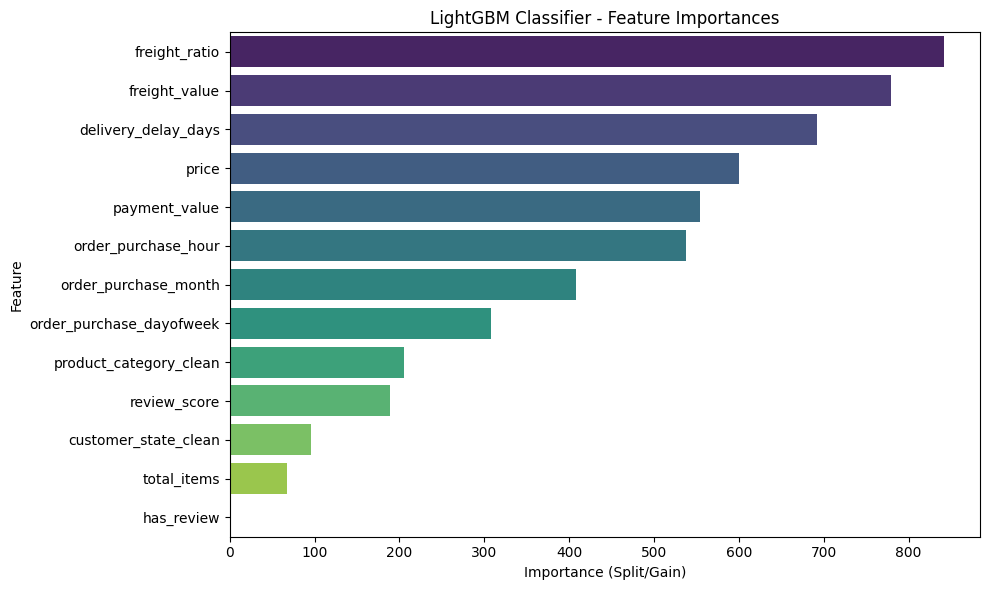

,Feature,Importance
6,freight_ratio,842
1,freight_value,779
5,delivery_delay_days,692
0,price,600
3,payment_value,554
8,order_purchase_hour,538
10,order_purchase_month,408
9,order_purchase_dayofweek,308
11,product_category_clean,205
4,review_score,189


In [136]:
import matplotlib.pyplot as plt
import seaborn as sns

# Extract feature importances
feature_importances = pd.DataFrame({
    'Feature': X_train_adv_final.columns,
    'Importance': lgb_model.feature_importances_
}).sort_values(by='Importance', ascending=False)

# Plot feature importances
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=feature_importances, palette='viridis')
plt.title('LightGBM Classifier - Feature Importances')
plt.xlabel('Importance (Split/Gain)')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

display(feature_importances)

In [137]:
import numpy as np
import pandas as pd
import lightgbm as lgb
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report, roc_auc_score

# 1. Advanced Feature Engineering: Interaction Features
# Let's add 'value_per_item' to prevent price-to-quantity distortions
customer_dataset_advanced['value_per_item'] = customer_dataset_advanced['price'] / (customer_dataset_advanced['total_items'] + 1e-5)

# Update feature column list with richer signal
advanced_cols_v2 = [
    'price', 'freight_value', 'total_items', 'payment_value', 'review_score',
    'delivery_delay_days', 'freight_ratio', 'has_review', 'value_per_item',
    'order_purchase_hour', 'order_purchase_dayofweek', 'order_purchase_month',
    'product_category_clean', 'customer_state_clean'
]

# Categorical Column Mapping
features_df_adv_v2 = customer_dataset_advanced[['customer_unique_id'] + advanced_cols_v2].copy()
for col in ['product_category_clean', 'customer_state_clean']:
    features_df_adv_v2[col] = features_df_adv_v2[col].astype('category')

# Fill numerical NaNs safely
features_df_adv_v2['review_score'] = features_df_adv_v2['review_score'].fillna(features_df_adv_v2['review_score'].median())

# Re-merge onto train and test splits
X_train_v2 = pd.merge(X_train[['customer_unique_id']], features_df_adv_v2, on='customer_unique_id', how='left').drop(columns=['customer_unique_id'])
X_test_v2 = pd.merge(X_test[['customer_unique_id']], features_df_adv_v2, on='customer_unique_id', how='left').drop(columns=['customer_unique_id'])

# 2. Hyperparameter Tuning Setup
estimator = lgb.LGBMClassifier(random_state=42, class_weight='balanced', verbose=-1)

param_grid = {
    'n_estimators': [100, 150, 200],
    'learning_rate': [0.01, 0.03, 0.05],
    'num_leaves': [15, 31, 63],
    'max_depth': [4, 6, -1],
    'subsample': [0.8, 1.0]
}

# 3. Perform 5-Fold Stratified Cross-Validation Search
grid_search = GridSearchCV(
    estimator=estimator,
    param_grid=param_grid,
    scoring='roc_auc',
    cv=5,
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train_v2, y_train)

# 4. Evaluate Tuned Model
best_lgb = grid_search.best_estimator_
y_pred_tuned = best_lgb.predict(X_test_v2)
y_proba_tuned = best_lgb.predict_proba(X_test_v2)[:, 1]

print(f"Best Hyperparameters found: {grid_search.best_params_}\n")
print("Tuned LightGBM Classification Report:")
print(classification_report(y_test, y_pred_tuned))
print(f"Tuned LightGBM ROC AUC Score: {roc_auc_score(y_test, y_proba_tuned):.4f}")

Fitting 5 folds for each of 162 candidates, totalling 810 fits
Best Hyperparameters found: {'learning_rate': 0.01, 'max_depth': 6, 'n_estimators': 100, 'num_leaves': 15, 'subsample': 0.8}

Tuned LightGBM Classification Report:
              precision    recall  f1-score   support

           0       0.57      0.54      0.55       349
           1       0.56      0.58      0.57       348

    accuracy                           0.56       697
   macro avg       0.56      0.56      0.56       697
weighted avg       0.56      0.56      0.56       697

Tuned LightGBM ROC AUC Score: 0.5793


In [138]:
y_train.value_counts()

,count
reordered_180,
1,1394
0,1393


In [139]:
import pandas as pd
import numpy as np
import lightgbm as lgb
from sklearn.metrics import classification_report, roc_auc_score

# 1. Retrieve the seller state for each customer's first order
sellers = pd.read_csv(f"{path}/olist_sellers_dataset.csv")
first_order_items = pd.merge(first_orders, items, on='order_id', how='inner')
first_order_items_sellers = pd.merge(first_order_items, sellers, on='seller_id', how='left')

# Group at customer level to get the first seller's state
seller_state_df = first_order_items_sellers.groupby('customer_unique_id')['seller_state'].first().reset_index()

# 2. Merge seller state back into customer_dataset_advanced
if 'seller_state' not in customer_dataset_advanced.columns:
    customer_dataset_advanced = pd.merge(customer_dataset_advanced, seller_state_df, on='customer_unique_id', how='left')

# 3. Create the binary state_match feature (1 if customer_state == seller_state, else 0)
customer_dataset_advanced['state_match'] = (customer_dataset_advanced['customer_state'] == customer_dataset_advanced['seller_state']).astype(int)

print("State match distribution:")
print(customer_dataset_advanced['state_match'].value_counts())


State match distribution:
state_match
0    59806
1    33552
Name: count, dtype: int64


In [140]:
# 4. Update the feature set to include the new 'state_match' feature
advanced_cols_v3 = [
    'price', 'freight_value', 'total_items', 'payment_value', 'review_score',
    'delivery_delay_days', 'freight_ratio', 'has_review', 'value_per_item',
    'order_purchase_hour', 'order_purchase_dayofweek', 'order_purchase_month',
    'product_category_clean', 'customer_state_clean', 'state_match'
]

# Re-extract and format features
features_df_adv_v3 = customer_dataset_advanced[['customer_unique_id'] + advanced_cols_v3].copy()
for col in ['product_category_clean', 'customer_state_clean']:
    features_df_adv_v3[col] = features_df_adv_v3[col].astype('category')

features_df_adv_v3['review_score'] = features_df_adv_v3['review_score'].fillna(features_df_adv_v3['review_score'].median())

# Re-merge onto train and test splits (180 days scenario for parity)
X_train_v3 = pd.merge(X_train[['customer_unique_id']], features_df_adv_v3, on='customer_unique_id', how='left').drop(columns=['customer_unique_id'])
X_test_v3 = pd.merge(X_test[['customer_unique_id']], features_df_adv_v3, on='customer_unique_id', how='left').drop(columns=['customer_unique_id'])

# 5. Initialize and Train LightGBM with the optimal hyperparameters
lgb_model_v3 = lgb.LGBMClassifier(
    learning_rate=0.01,
    max_depth=6,
    n_estimators=100,
    num_leaves=15,
    subsample=0.8,
    random_state=42,
    class_weight='balanced',
    verbose=-1
)

lgb_model_v3.fit(X_train_v3, y_train)

# 6. Predict and Evaluate
y_pred_v3 = lgb_model_v3.predict(X_test_v3)
y_proba_v3 = lgb_model_v3.predict_proba(X_test_v3)[:, 1]

print("\nLightGBM with state_match Classification Report:")
print(classification_report(y_test, y_pred_v3))
print(f"LightGBM with state_match ROC AUC Score: {roc_auc_score(y_test, y_proba_v3):.4f}")



LightGBM with state_match Classification Report:
              precision    recall  f1-score   support

           0       0.57      0.55      0.56       349
           1       0.56      0.58      0.57       348

    accuracy                           0.57       697
   macro avg       0.57      0.57      0.57       697
weighted avg       0.57      0.57      0.57       697

LightGBM with state_match ROC AUC Score: 0.5789


In [141]:
import pandas as pd
import numpy as np
import lightgbm as lgb
from sklearn.metrics import classification_report, roc_auc_score

# 1. Retrieve the payment type for each customer's first order
first_order_payments = pd.merge(first_orders, payments, on='order_id', how='inner')

# Group at customer level to get the first/dominant payment type
payment_type_df = first_order_payments.groupby('customer_unique_id')['payment_type'].first().reset_index()

# 2. Merge payment type back into customer_dataset_advanced
if 'payment_type' in customer_dataset_advanced.columns:
    customer_dataset_advanced.drop(columns=['payment_type'], inplace=True)
customer_dataset_advanced = pd.merge(customer_dataset_advanced, payment_type_df, on='customer_unique_id', how='left')

# Handle missing payment types safely
customer_dataset_advanced['payment_type'] = customer_dataset_advanced['payment_type'].fillna('unknown')

# Map rare payment types to 'other'
top_payments = customer_dataset_advanced['payment_type'].value_counts().index[:3]
customer_dataset_advanced['payment_type_clean'] = customer_dataset_advanced['payment_type'].apply(
    lambda x: x if x in top_payments else 'other'
)

print("Cleaned Payment Type Distribution:")
print(customer_dataset_advanced['payment_type_clean'].value_counts())


Cleaned Payment Type Distribution:
payment_type_clean
credit_card    70842
boleto         18625
voucher         2450
other           1441
Name: count, dtype: int64


In [142]:
# 3. Update the feature set to include 'payment_type_clean'
advanced_cols_v4 = [
    'price', 'freight_value', 'total_items', 'payment_value', 'review_score',
    'delivery_delay_days', 'freight_ratio', 'has_review', 'value_per_item',
    'order_purchase_hour', 'order_purchase_dayofweek', 'order_purchase_month',
    'product_category_clean', 'customer_state_clean', 'state_match', 'payment_type_clean'
]

# Re-extract and format features
features_df_adv_v4 = customer_dataset_advanced[['customer_unique_id'] + advanced_cols_v4].copy()
for col in ['product_category_clean', 'customer_state_clean', 'payment_type_clean']:
    features_df_adv_v4[col] = features_df_adv_v4[col].astype('category')

features_df_adv_v4['review_score'] = features_df_adv_v4['review_score'].fillna(features_df_adv_v4['review_score'].median())

# Re-merge onto train and test splits
X_train_v4 = pd.merge(X_train[['customer_unique_id']], features_df_adv_v4, on='customer_unique_id', how='left').drop(columns=['customer_unique_id'])
X_test_v4 = pd.merge(X_test[['customer_unique_id']], features_df_adv_v4, on='customer_unique_id', how='left').drop(columns=['customer_unique_id'])

# 4. Initialize and Train LightGBM with the optimal hyperparameters
lgb_model_v4 = lgb.LGBMClassifier(
    learning_rate=0.01,
    max_depth=6,
    n_estimators=100,
    num_leaves=15,
    subsample=0.8,
    random_state=42,
    class_weight='balanced',
    verbose=-1
)

lgb_model_v4.fit(X_train_v4, y_train)

# 5. Predict and Evaluate
y_pred_v4 = lgb_model_v4.predict(X_test_v4)
y_proba_v4 = lgb_model_v4.predict_proba(X_test_v4)[:, 1]

print("\nLightGBM with payment_type Classification Report:")
print(classification_report(y_test, y_pred_v4))
print(f"LightGBM with payment_type ROC AUC Score: {roc_auc_score(y_test, y_proba_v4):.4f}")



LightGBM with payment_type Classification Report:
              precision    recall  f1-score   support

           0       0.57      0.56      0.57       349
           1       0.57      0.57      0.57       348

    accuracy                           0.57       697
   macro avg       0.57      0.57      0.57       697
weighted avg       0.57      0.57      0.57       697

LightGBM with payment_type ROC AUC Score: 0.5791


In [143]:
import pandas as pd
import numpy as np
import lightgbm as lgb
from sklearn.metrics import classification_report, roc_auc_score

# 1. Convert first order purchase timestamps to dates
customer_dataset_advanced['order_purchase_date'] = pd.to_datetime(customer_dataset_advanced['order_purchase_timestamp']).dt.date

# 2. Define Black Friday dates for the years present in the dataset
black_friday_dates = {
    2016: pd.to_datetime('2016-11-25').date(),
    2017: pd.to_datetime('2017-11-24').date(),
    2018: pd.to_datetime('2018-11-23').date()
}

# 3. Create a binary indicator: 1 if ordered on Black Friday, 0 otherwise
customer_dataset_advanced['ordered_on_black_friday'] = customer_dataset_advanced.apply(
    lambda row: 1 if row['order_purchase_timestamp'].year in black_friday_dates
                 and row['order_purchase_date'] == black_friday_dates[row['order_purchase_timestamp'].year]
                 else 0,
    axis=1
)

print("Black Friday purchase distribution:")
print(customer_dataset_advanced['ordered_on_black_friday'].value_counts())


Black Friday purchase distribution:
ordered_on_black_friday
0    92244
1     1114
Name: count, dtype: int64


In [144]:
# 4. Update the feature set to include the new 'ordered_on_black_friday' feature
advanced_cols_v6 = [
    'price', 'freight_value', 'total_items', 'payment_value', 'review_score',
    'delivery_delay_days', 'freight_ratio', 'has_review', 'value_per_item',
    'order_purchase_hour', 'order_purchase_dayofweek', 'order_purchase_month',
    'product_category_clean', 'customer_state_clean', 'state_match', 'payment_type_clean',
    'ordered_on_black_friday'
]

# Re-extract and format features
features_df_adv_v6 = customer_dataset_advanced[['customer_unique_id'] + advanced_cols_v6].copy()
for col in ['product_category_clean', 'customer_state_clean', 'payment_type_clean']:
    features_df_adv_v6[col] = features_df_adv_v6[col].astype('category')

features_df_adv_v6['review_score'] = features_df_adv_v6['review_score'].fillna(features_df_adv_v6['review_score'].median())

# Re-merge onto train and test splits
X_train_v6 = pd.merge(X_train[['customer_unique_id']], features_df_adv_v6, on='customer_unique_id', how='left').drop(columns=['customer_unique_id'])
X_test_v6 = pd.merge(X_test[['customer_unique_id']], features_df_adv_v6, on='customer_unique_id', how='left').drop(columns=['customer_unique_id'])

# 5. Initialize and Train LightGBM with the updated feature
lgb_model_v6 = lgb.LGBMClassifier(
    learning_rate=0.01,
    max_depth=6,
    n_estimators=100,
    num_leaves=15,
    subsample=0.8,
    random_state=42,
    class_weight='balanced',
    verbose=-1
)

lgb_model_v6.fit(X_train_v6, y_train)

# 6. Predict and Evaluate
y_pred_v6 = lgb_model_v6.predict(X_test_v6)
y_proba_v6 = lgb_model_v6.predict_proba(X_test_v6)[:, 1]

print("\nLightGBM with Black Friday Indicator Classification Report:")
print(classification_report(y_test, y_pred_v6))
print(f"LightGBM ROC AUC Score: {roc_auc_score(y_test, y_proba_v6):.4f}")



LightGBM with Black Friday Indicator Classification Report:
              precision    recall  f1-score   support

           0       0.57      0.56      0.57       349
           1       0.57      0.57      0.57       348

    accuracy                           0.57       697
   macro avg       0.57      0.57      0.57       697
weighted avg       0.57      0.57      0.57       697

LightGBM ROC AUC Score: 0.5791


In [145]:
advanced_cols_v6

['price',
 'freight_value',
 'total_items',
 'payment_value',
 'review_score',
 'delivery_delay_days',
 'freight_ratio',
 'has_review',
 'value_per_item',
 'order_purchase_hour',
 'order_purchase_dayofweek',
 'order_purchase_month',
 'product_category_clean',
 'customer_state_clean',
 'state_match',
 'payment_type_clean',
 'ordered_on_black_friday']

In [146]:
import pandas as pd
import numpy as np
import lightgbm as lgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, roc_auc_score

# 1. Prepare features and target on the entire valid_customers_df dataset (55,907 customers)
X_full = valid_customers_df[['customer_unique_id']].copy()
y_full = valid_customers_df['reordered_180']

# 2. Extract and format the full v6 features
features_df_adv_v6 = customer_dataset_advanced[['customer_unique_id'] + advanced_cols_v6].copy()
for col in ['product_category_clean', 'customer_state_clean', 'payment_type_clean']:
    features_df_adv_v6[col] = features_df_adv_v6[col].astype('category')

features_df_adv_v6['review_score'] = features_df_adv_v6['review_score'].fillna(features_df_adv_v6['review_score'].median())

# 3. Merge features onto our full training customer base
X_full_enriched = pd.merge(X_full, features_df_adv_v6, on='customer_unique_id', how='left').drop(columns=['customer_unique_id'])

# 4. Train/Test Split (80% Train, 20% Test) stratified to handle the heavy class imbalance
X_train_f, X_test_f, y_train_f, y_test_f = train_test_split(
    X_full_enriched, y_full, test_size=0.2, random_state=42, stratify=y_full
)

print(f"Full Training set size: {X_train_f.shape[0]} rows")
print(f"Full Testing set size: {X_test_f.shape[0]} rows")
print(f"Class Distribution in Training Set:\n{y_train_f.value_counts(normalize=True)}")

# 5. Initialize and Train LightGBM with class_weight='balanced' to handle the extreme imbalance
lgb_model_full = lgb.LGBMClassifier(
    learning_rate=0.01,
    max_depth=6,
    n_estimators=100,
    num_leaves=15,
    subsample=0.8,
    random_state=42,
    class_weight='balanced',
    verbose=-1
)

lgb_model_full.fit(X_train_f, y_train_f)

# 6. Predict and Evaluate
y_pred_f = lgb_model_full.predict(X_test_f)
y_proba_f = lgb_model_full.predict_proba(X_test_f)[:, 1]

print("\nLightGBM on Full Dataset Classification Report:")
print(classification_report(y_test_f, y_pred_f))
print(f"LightGBM on Full Dataset ROC AUC Score: {roc_auc_score(y_test_f, y_proba_f):.4f}")

Full Training set size: 44725 rows
Full Testing set size: 11182 rows
Class Distribution in Training Set:
reordered_180
0    0.968832
1    0.031168
Name: proportion, dtype: float64

LightGBM on Full Dataset Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.62      0.76     10834
           1       0.04      0.53      0.08       348

    accuracy                           0.62     11182
   macro avg       0.51      0.57      0.42     11182
weighted avg       0.95      0.62      0.74     11182

LightGBM on Full Dataset ROC AUC Score: 0.5931


In [147]:
X_train_f

,price,freight_value,total_items,payment_value,review_score,delivery_delay_days,freight_ratio,has_review,value_per_item,order_purchase_hour,order_purchase_dayofweek,order_purchase_month,product_category_clean,customer_state_clean,state_match,payment_type_clean,ordered_on_black_friday
26081,152.00,15.81,1,167.81,5.0,-13.0,0.104013,1,151.998480,17,0,12,other,other,0,credit_card,0
54162,138.00,25.81,1,163.81,5.0,-1.0,0.187029,1,137.998620,18,1,1,cama_mesa_banho,RS,0,credit_card,0
29539,173.00,15.96,1,188.96,5.0,-3.0,0.092254,1,172.998270,15,4,8,cama_mesa_banho,RJ,0,boleto,0
53575,57.00,20.80,1,77.80,5.0,-7.0,0.364912,1,56.999430,12,2,2,cama_mesa_banho,other,0,boleto,0
4227,135.50,12.15,1,147.65,5.0,-15.0,0.089668,1,135.498645,23,4,6,other,SP,1,credit_card,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
55216,51.06,17.61,1,68.67,4.0,-18.0,0.344888,1,51.059489,20,6,6,utilidades_domesticas,RJ,0,credit_card,0
36796,209.99,28.01,1,238.00,5.0,-15.0,0.133387,1,209.987900,19,1,11,automotivo,other,0,credit_card,0
8114,35.00,15.10,1,50.10,5.0,-21.0,0.431429,1,34.999650,23,2,1,other,MG,0,credit_card,0
36920,129.99,33.19,1,163.18,5.0,-12.0,0.255327,1,129.988700,16,1,4,informatica_acessorios,SP,0,boleto,0


In [148]:
import pandas as pd
import numpy as np
import lightgbm as lgb
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, roc_auc_score

# 1. Prepare features and target on the entire dataset
X_full = valid_customers_df[['customer_unique_id']].copy()
y_full = valid_customers_df['reordered_180']

# 2. Extract the features
features_df_v7 = customer_dataset_advanced[['customer_unique_id'] + advanced_cols_v6].copy()

# Fill missing review scores safely
features_df_v7['review_score'] = features_df_v7['review_score'].fillna(features_df_v7['review_score'].median())

# 3. Separate numerical and categorical features
categorical_cols = ['product_category_clean', 'customer_state_clean', 'payment_type_clean']
numerical_cols = [col for col in advanced_cols_v6 if col not in categorical_cols]

# Perform One-Hot Encoding on categorical features
features_encoded = pd.get_dummies(features_df_v7[categorical_cols], drop_first=True, dtype=int)

# Combine numerical features and one-hot encoded features
X_processed_full = pd.concat([features_df_v7[['customer_unique_id']], features_df_v7[numerical_cols], features_encoded], axis=1)

# Merge with our label dataset to align rows
X_full_enriched = pd.merge(X_full, X_processed_full, on='customer_unique_id', how='left').drop(columns=['customer_unique_id'])

# 4. Stratified Train/Test Split (80% Train, 20% Test)
X_train_v7, X_test_v7, y_train_v7, y_test_v7 = train_test_split(
    X_full_enriched, y_full, test_size=0.2, random_state=42, stratify=y_full
)

# 5. Standardize all columns
scaler = StandardScaler()
X_train_scaled_v7 = scaler.fit_transform(X_train_v7)
X_test_scaled_v7 = scaler.transform(X_test_v7)

# Convert scaled arrays back to DataFrames to preserve column names for reference if needed
column_names = X_train_v7.columns
X_train_scaled_df = pd.DataFrame(X_train_scaled_v7, columns=column_names)
X_test_scaled_df = pd.DataFrame(X_test_scaled_v7, columns=column_names)

print(f"Scaled training set shape: {X_train_scaled_df.shape}")
print(f"Scaled testing set shape: {X_test_scaled_df.shape}")


Scaled training set shape: (44725, 32)
Scaled testing set shape: (11182, 32)


In [149]:
# 6. Initialize and Train LightGBM with class_weight='balanced'
lgb_model_v7 = lgb.LGBMClassifier(
    learning_rate=0.01,
    max_depth=6,
    n_estimators=100,
    num_leaves=15,
    subsample=0.8,
    random_state=42,
    class_weight='balanced',
    verbose=-1
)

lgb_model_v7.fit(X_train_scaled_df, y_train_v7)

# 7. Predict and Evaluate
y_pred_v7 = lgb_model_v7.predict(X_test_scaled_df)
y_proba_v7 = lgb_model_v7.predict_proba(X_test_scaled_df)[:, 1]

print("\nLightGBM with One-Hot Encoding and Standardization Classification Report:")
print(classification_report(y_test_v7, y_pred_v7))
print(f"LightGBM ROC AUC Score: {roc_auc_score(y_test_v7, y_proba_v7):.4f}")



LightGBM with One-Hot Encoding and Standardization Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.63      0.77     10834
           1       0.04      0.53      0.08       348

    accuracy                           0.63     11182
   macro avg       0.51      0.58      0.43     11182
weighted avg       0.95      0.63      0.75     11182

LightGBM ROC AUC Score: 0.5928


In [160]:

from catboost import CatBoostClassifier
from sklearn.metrics import classification_report, roc_auc_score
import numpy as np

# 1. Initialize CatBoost Classifier with a low learning rate
# We will use auto_class_weights='Balanced' to manage the 3.1% class imbalance
m = CatBoostClassifier(iterations=2000, learning_rate=0.03, depth=5,
                          l2_leaf_reg=10, auto_class_weights='Balanced',
                          eval_metric='AUC', early_stopping_rounds=150,
                          random_seed=42, verbose=100)
y_shuf = y_train_v7.sample(frac=1, random_state=0).values

# 2. Fit the model using the standardized training data
# Fix: Use y_test_v7 instead of y_shuf for the evaluation set target
m.fit(X_train_scaled_df, y_shuf, eval_set=(X_test_scaled_df, y_test_v7))

# 3. Predict and Evaluate
y_pred_cat = m.predict(X_test_scaled_df)
y_proba_cat = m.predict_proba(X_test_scaled_df)[:, 1]

print("\nCatBoost Classifier with Low Learning Rate Classification Report:")
print(classification_report(y_test_v7, y_pred_cat))
print(f"CatBoost ROC AUC Score: {roc_auc_score(y_test_v7, y_proba_cat):.4f}")

0:	test: 0.5097487	best: 0.5097487 (0)	total: 35ms	remaining: 1m 10s
100:	test: 0.4992592	best: 0.5247403 (7)	total: 2.27s	remaining: 42.8s
Stopped by overfitting detector  (150 iterations wait)

bestTest = 0.5247402547
bestIteration = 7

Shrink model to first 8 iterations.

CatBoost Classifier with Low Learning Rate Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.66      0.79     10834
           1       0.03      0.37      0.06       348

    accuracy                           0.65     11182
   macro avg       0.50      0.52      0.43     11182
weighted avg       0.94      0.65      0.77     11182

CatBoost ROC AUC Score: 0.5247


In [152]:
X_train_scaled_df

,price,freight_value,total_items,payment_value,review_score,delivery_delay_days,freight_ratio,has_review,value_per_item,order_purchase_hour,...,product_category_clean_telefonia,product_category_clean_utilidades_domesticas,customer_state_clean_PR,customer_state_clean_RJ,customer_state_clean_RS,customer_state_clean_SP,customer_state_clean_other,payment_type_clean_credit_card,payment_type_clean_other,payment_type_clean_voucher
0,0.080345,-0.313687,-0.25796,0.048238,0.668951,-0.100409,-0.687110,0.086216,0.154482,0.410609,...,-0.221073,-0.235388,-0.230588,-0.394569,-0.248285,-0.811940,1.783339,0.575552,-0.101492,-0.169495
1,0.012346,0.197135,-0.25796,0.029616,0.668951,1.054831,-0.401902,0.086216,0.077622,0.596633,...,-0.221073,-0.235388,-0.230588,-0.394569,4.027629,-0.811940,-0.560746,0.575552,-0.101492,-0.169495
2,0.182344,-0.306025,-0.25796,0.146697,0.668951,0.862291,-0.727508,0.086216,0.269771,0.038561,...,-0.221073,-0.235388,-0.230588,2.534410,-0.248285,-0.811940,-0.560746,-1.737464,-0.101492,-0.169495
3,-0.381076,-0.058787,-0.25796,-0.370787,0.668951,0.477211,0.209231,0.086216,-0.367064,-0.519511,...,-0.221073,-0.235388,-0.230588,-0.394569,-0.248285,-0.811940,1.783339,-1.737464,-0.101492,-0.169495
4,0.000204,-0.500649,-0.25796,-0.045613,0.668951,-0.292949,-0.736394,0.086216,0.063898,1.526753,...,-0.221073,-0.235388,-0.230588,-0.394569,-0.248285,1.231618,-0.560746,0.575552,-0.101492,-0.169495
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
44720,-0.409927,-0.221739,-0.25796,-0.413290,-0.104945,-0.581759,0.140437,0.086216,-0.399674,0.968681,...,-0.221073,4.248309,-0.230588,2.534410,-0.248285,-0.811940,-0.560746,0.575552,-0.101492,-0.169495
44721,0.362007,0.309516,-0.25796,0.374994,0.668951,-0.292949,-0.586192,0.086216,0.472844,0.782657,...,-0.221073,-0.235388,-0.230588,-0.394569,-0.248285,-0.811940,1.783339,0.575552,-0.101492,-0.169495
44722,-0.487931,-0.349956,-0.25796,-0.499739,0.668951,-0.870569,0.437754,0.086216,-0.487843,1.526753,...,-0.221073,-0.235388,-0.230588,-0.394569,-0.248285,-0.811940,-0.560746,0.575552,-0.101492,-0.169495
44723,-0.026559,0.574123,-0.25796,0.026684,0.668951,-0.004139,-0.167257,0.086216,0.033648,0.224585,...,-0.221073,-0.235388,-0.230588,-0.394569,-0.248285,1.231618,-0.560746,-1.737464,-0.101492,-0.169495


In [159]:
   from sklearn.model_selection import train_test_split
   from catboost import CatBoostClassifier

   cat_cols = ['product_category_clean', 'customer_state_clean', 'payment_type_clean']
   Xtr, Xva, ytr, yva = train_test_split(X_train_raw, y_train, test_size=0.15,
                                         stratify=y_train, random_state=42)
   m = CatBoostClassifier(iterations=2000, learning_rate=0.03, depth=5,
                          l2_leaf_reg=10, auto_class_weights='Balanced',
                          eval_metric='AUC', early_stopping_rounds=150,
                          random_seed=42, verbose=100)
   m.fit(Xtr, ytr, cat_features=cat_cols, eval_set=(Xva, yva))

NameError: name 'X_train_raw' is not defined

In [161]:
import pandas as pd
import numpy as np

# 1. Update Category Clean to Top 15 instead of Top 10
top_15_categories = customer_dataset_advanced['product_category_name'].value_counts().index[:15]
customer_dataset_advanced['product_category_clean'] = customer_dataset_advanced['product_category_name'].apply(
    lambda x: x if x in top_15_categories else 'other'
)

# 2. Load and process Geolocation table
geo = pd.read_csv(f"{path}/olist_geolocation_dataset.csv")
geo_coords = geo.groupby('geolocation_zip_code_prefix').agg({
    'geolocation_lat': 'mean',
    'geolocation_lng': 'mean'
}).reset_index()

# Merge latitude/longitude for customers using zip code prefix
customer_dataset_advanced = pd.merge(
    customer_dataset_advanced,
    geo_coords,
    left_on='customer_zip_code_prefix',
    right_on='geolocation_zip_code_prefix',
    how='left'
).drop(columns=['geolocation_zip_code_prefix'])

# Handle missing geolocation values by filling with average coordinate values
customer_dataset_advanced['geolocation_lat'] = customer_dataset_advanced['geolocation_lat'].fillna(customer_dataset_advanced['geolocation_lat'].mean())
customer_dataset_advanced['geolocation_lng'] = customer_dataset_advanced['geolocation_lng'].fillna(customer_dataset_advanced['geolocation_lng'].mean())

print("Top 15 product category distribution:")
print(customer_dataset_advanced['product_category_clean'].value_counts())
print(f"\nLatitude range: {customer_dataset_advanced['geolocation_lat'].min()} to {customer_dataset_advanced['geolocation_lat'].max()}")


Top 15 product category distribution:
product_category_clean
other                     19704
cama_mesa_banho            8736
beleza_saude               8353
esporte_lazer              7205
informatica_acessorios     6287
moveis_decoracao           5927
utilidades_domesticas      5511
relogios_presentes         5315
telefonia                  3990
automotivo                 3705
brinquedos                 3673
cool_stuff                 3474
ferramentas_jardim         3332
perfumaria                 2990
bebes                      2693
eletronicos                2463
Name: count, dtype: int64

Latitude range: -33.68994828174511 to 42.18400274298598


In [162]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 3. Choose updated feature set incorporating coords
advanced_cols_v8 = [
    'price', 'freight_value', 'total_items', 'payment_value', 'review_score',
    'delivery_delay_days', 'freight_ratio', 'has_review', 'value_per_item',
    'order_purchase_hour', 'order_purchase_dayofweek', 'order_purchase_month',
    'product_category_clean', 'customer_state_clean', 'state_match', 'payment_type_clean',
    'ordered_on_black_friday', 'geolocation_lat', 'geolocation_lng'
]

# Prepare features on the entire dataset
X_full = valid_customers_df[['customer_unique_id']].copy()
y_full = valid_customers_df['reordered_180']

features_df_v8 = customer_dataset_advanced[['customer_unique_id'] + advanced_cols_v8].copy()

# Fill missing review scores
features_df_v8['review_score'] = features_df_v8['review_score'].fillna(features_df_v8['review_score'].median())

categorical_cols = ['product_category_clean', 'customer_state_clean', 'payment_type_clean']
numerical_cols = [col for col in advanced_cols_v8 if col not in categorical_cols]

# Encode categorical variables
features_encoded = pd.get_dummies(features_df_v8[categorical_cols], drop_first=True, dtype=int)
X_processed_full = pd.concat([features_df_v8[['customer_unique_id']], features_df_v8[numerical_cols], features_encoded], axis=1)
X_full_enriched = pd.merge(X_full, X_processed_full, on='customer_unique_id', how='left').drop(columns=['customer_unique_id'])

# Stratified Train/Test Split
X_train_v8, X_test_v8, y_train_v8, y_test_v8 = train_test_split(
    X_full_enriched, y_full, test_size=0.2, random_state=42, stratify=y_full
)

# Normalize numerical features
scaler = StandardScaler()
X_train_scaled_v8 = scaler.fit_transform(X_train_v8)
X_test_scaled_v8 = scaler.transform(X_test_v8)

X_train_scaled_df_v8 = pd.DataFrame(X_train_scaled_v8, columns=X_train_v8.columns)
X_test_scaled_df_v8 = pd.DataFrame(X_test_scaled_v8, columns=X_test_v8.columns)

print(f"Scaled training configuration shape: {X_train_scaled_df_v8.shape}")


Scaled training configuration shape: (44725, 39)


In [164]:
from catboost import CatBoostClassifier
from sklearn.metrics import classification_report, roc_auc_score
import numpy as np

# 1. Initialize CatBoost Classifier with a low learning rate
# We will use auto_class_weights='Balanced' to manage the 3.1% class imbalance
m = CatBoostClassifier(iterations=2000, learning_rate=0.03, depth=5,
                          l2_leaf_reg=10, auto_class_weights='Balanced',
                          eval_metric='AUC', early_stopping_rounds=150,
                          random_seed=42, verbose=100)
y_shuf = y_train_v7.sample(frac=1, random_state=0).values

# 2. Fit the model using the standardized training data
# Fix: Use y_test_v7 instead of y_shuf for the evaluation set target
m.fit(X_train_scaled_df_v8, y_shuf, eval_set=(X_test_scaled_df_v8, y_test_v7))

# 3. Predict and Evaluate
y_pred_cat = m.predict(X_test_scaled_df_v8)
y_proba_cat = m.predict_proba(X_test_scaled_df_v8)[:, 1]

print("\nCatBoost Classifier with Low Learning Rate Classification Report:")
print(classification_report(y_test_v7, y_pred_cat))
print(f"CatBoost ROC AUC Score: {roc_auc_score(y_test_v7, y_proba_cat):.4f}")

0:	test: 0.4880196	best: 0.4880196 (0)	total: 26.6ms	remaining: 53.2s
100:	test: 0.4906674	best: 0.5202103 (7)	total: 2.46s	remaining: 46.2s
Stopped by overfitting detector  (150 iterations wait)

bestTest = 0.5202102948
bestIteration = 7

Shrink model to first 8 iterations.

CatBoost Classifier with Low Learning Rate Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.59      0.73     10834
           1       0.04      0.47      0.07       348

    accuracy                           0.58     11182
   macro avg       0.50      0.53      0.40     11182
weighted avg       0.94      0.58      0.71     11182

CatBoost ROC AUC Score: 0.5202


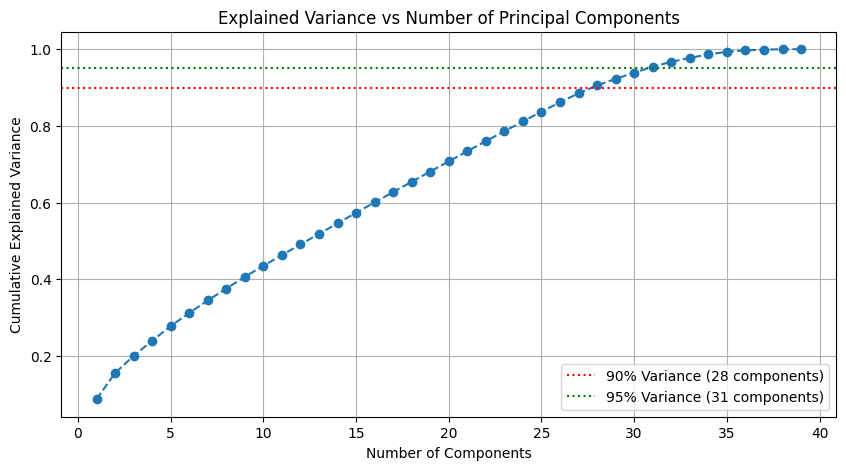

Components to retain 90% variance: 28
Components to retain 95% variance: 31


In [166]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import numpy as np

# 1. Initialize PCA without restricting components first to analyze variance
pca_temp = PCA(random_state=42)
pca_temp.fit(X_train_scaled_df_v8)

cumulative_variance = np.cumsum(pca_temp.explained_variance_ratio_)

# Find number of components to explain 90% and 95% of the variance
n_90 = np.argmax(cumulative_variance >= 0.90) + 1
n_95 = np.argmax(cumulative_variance >= 0.95) + 1

# Plot cumulative explained variance
plt.figure(figsize=(10, 5))
plt.plot(range(1, len(cumulative_variance) + 1), cumulative_variance, marker='o', linestyle='--')
plt.axhline(y=0.90, color='r', linestyle=':', label=f'90% Variance ({n_90} components)')
plt.axhline(y=0.95, color='g', linestyle=':', label=f'95% Variance ({n_95} components)')
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('Explained Variance vs Number of Principal Components')
plt.legend()
plt.grid(True)
plt.show()

print(f"Components to retain 90% variance: {n_90}")
print(f"Components to retain 95% variance: {n_95}")

In [167]:
# 2. Apply PCA to reduce the feature space to retain 95% of the variance
pca = PCA(n_components=n_95, random_state=42)

X_train_pca = pca.fit_transform(X_train_scaled_df_v8)
X_test_pca = pca.transform(X_test_scaled_df_v8)

# Convert to DataFrames for easier viewing/handling
pca_cols = [f'PC{i}' for i in range(1, n_95 + 1)]
X_train_pca_df = pd.DataFrame(X_train_pca, columns=pca_cols)
X_test_pca_df = pd.DataFrame(X_test_pca, columns=pca_cols)

print(f"Reduced training feature shape: {X_train_pca_df.shape}")
print(f"Reduced test feature shape: {X_test_pca_df.shape}")

Reduced training feature shape: (44725, 31)
Reduced test feature shape: (11182, 31)


In [169]:
from catboost import CatBoostClassifier
from sklearn.metrics import classification_report, roc_auc_score

# 3. Train the CatBoost Classifier on the PCA-reduced components
m_pca = CatBoostClassifier(iterations=2000, learning_rate=0.03, depth=5,
                              l2_leaf_reg=10, auto_class_weights='Balanced',
                              eval_metric='AUC', early_stopping_rounds=150,
                              random_seed=42, verbose=100)

# Fit using PCA-reduced datasets
m_pca.fit(X_train_pca_df, y_train_v8, eval_set=(X_test_pca_df, y_test_v8))

# 4. Predict and Evaluate
y_pred_pca = m_pca.predict(X_test_pca_df)
y_proba_pca = m_pca.predict_proba(X_test_pca_df)[:, 1]

print("\nCatBoost on PCA Components Classification Report:")
print(classification_report(y_test_v8, y_pred_pca))
print(f"CatBoost with PCA ROC AUC Score: {roc_auc_score(y_test_v8, y_proba_pca):.4f}")

0:	test: 0.5599935	best: 0.5599935 (0)	total: 21ms	remaining: 41.9s
100:	test: 0.5899885	best: 0.5935424 (36)	total: 1.89s	remaining: 35.5s
200:	test: 0.5959209	best: 0.5960729 (199)	total: 3.73s	remaining: 33.4s
300:	test: 0.5935224	best: 0.5982377 (243)	total: 7.4s	remaining: 41.8s
Stopped by overfitting detector  (150 iterations wait)

bestTest = 0.5982377212
bestIteration = 243

Shrink model to first 244 iterations.

CatBoost on PCA Components Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.64      0.77     10834
           1       0.04      0.50      0.08       348

    accuracy                           0.63     11182
   macro avg       0.51      0.57      0.42     11182
weighted avg       0.95      0.63      0.75     11182

CatBoost with PCA ROC AUC Score: 0.5982


In [170]:
import numpy as np
import pandas as pd

# 1. Create a random single input sample with 31 principal components
# We'll use a standard normal distribution since the input to PCA was standardized
np.random.seed(42)
random_pca_sample = np.random.normal(loc=0.0, scale=1.0, size=(1, 31))

# Convert to a DataFrame with correct feature names used during training
pca_cols = [f'PC{i}' for i in range(1, 32)]
random_sample_df = pd.DataFrame(random_pca_sample, columns=pca_cols)

# 2. Get predictions and probabilities from the PCA-trained CatBoost model
predicted_class = m_pca.predict(random_sample_df)[0]
predicted_proba = m_pca.predict_proba(random_sample_df)[0]

# 3. Display the details
print("Random Input PCA Features:")
display(random_sample_df)
print(f"\nPredicted Class: {predicted_class}")
print(f"Predicted Probabilities (Class 0 / Class 1): {predicted_proba}")

Random Input PCA Features:


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,...,PC22,PC23,PC24,PC25,PC26,PC27,PC28,PC29,PC30,PC31
0,0.496714,-0.138264,0.647689,1.52303,-0.234153,-0.234137,1.579213,0.767435,-0.469474,0.54256,...,-0.225776,0.067528,-1.424748,-0.544383,0.110923,-1.150994,0.375698,-0.600639,-0.291694,-0.601707



Predicted Class: 0
Predicted Probabilities (Class 0 / Class 1): [0.55449601 0.44550399]


In [165]:
X_train_scaled_df_v8

,price,freight_value,total_items,payment_value,review_score,delivery_delay_days,freight_ratio,has_review,value_per_item,order_purchase_hour,...,product_category_clean_telefonia,product_category_clean_utilidades_domesticas,customer_state_clean_PR,customer_state_clean_RJ,customer_state_clean_RS,customer_state_clean_SP,customer_state_clean_other,payment_type_clean_credit_card,payment_type_clean_other,payment_type_clean_voucher
0,0.080345,-0.313687,-0.25796,0.048238,0.668951,-0.100409,-0.687110,0.086216,0.154482,0.410609,...,-0.221073,-0.235388,-0.230588,-0.394569,-0.248285,-0.811940,1.783339,0.575552,-0.101492,-0.169495
1,0.012346,0.197135,-0.25796,0.029616,0.668951,1.054831,-0.401902,0.086216,0.077622,0.596633,...,-0.221073,-0.235388,-0.230588,-0.394569,4.027629,-0.811940,-0.560746,0.575552,-0.101492,-0.169495
2,0.182344,-0.306025,-0.25796,0.146697,0.668951,0.862291,-0.727508,0.086216,0.269771,0.038561,...,-0.221073,-0.235388,-0.230588,2.534410,-0.248285,-0.811940,-0.560746,-1.737464,-0.101492,-0.169495
3,-0.381076,-0.058787,-0.25796,-0.370787,0.668951,0.477211,0.209231,0.086216,-0.367064,-0.519511,...,-0.221073,-0.235388,-0.230588,-0.394569,-0.248285,-0.811940,1.783339,-1.737464,-0.101492,-0.169495
4,0.000204,-0.500649,-0.25796,-0.045613,0.668951,-0.292949,-0.736394,0.086216,0.063898,1.526753,...,-0.221073,-0.235388,-0.230588,-0.394569,-0.248285,1.231618,-0.560746,0.575552,-0.101492,-0.169495
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
44720,-0.409927,-0.221739,-0.25796,-0.413290,-0.104945,-0.581759,0.140437,0.086216,-0.399674,0.968681,...,-0.221073,4.248309,-0.230588,2.534410,-0.248285,-0.811940,-0.560746,0.575552,-0.101492,-0.169495
44721,0.362007,0.309516,-0.25796,0.374994,0.668951,-0.292949,-0.586192,0.086216,0.472844,0.782657,...,-0.221073,-0.235388,-0.230588,-0.394569,-0.248285,-0.811940,1.783339,0.575552,-0.101492,-0.169495
44722,-0.487931,-0.349956,-0.25796,-0.499739,0.668951,-0.870569,0.437754,0.086216,-0.487843,1.526753,...,-0.221073,-0.235388,-0.230588,-0.394569,-0.248285,-0.811940,-0.560746,0.575552,-0.101492,-0.169495
44723,-0.026559,0.574123,-0.25796,0.026684,0.668951,-0.004139,-0.167257,0.086216,0.033648,0.224585,...,-0.221073,-0.235388,-0.230588,-0.394569,-0.248285,1.231618,-0.560746,-1.737464,-0.101492,-0.169495


In [183]:

# Instantiate the pipeline with training artifacts
pipeline = PredictorPipeline(
    catboost_model=m_pca,
    pca_transformer=pca,
    scaler_transformer=scaler,
    top_15_categories=list(top_15_categories),
    top_states=list(top_states),
    top_payments=list(top_payments),
    black_friday_dates=black_friday_dates,
    columns_order=X_train_v8.columns
)

ModuleNotFoundError: No module named 'pipeline'

In [178]:
# Demo using a raw sample reconstructed from our datasets
sample_raw_input = pd.DataFrame([{
    'order_purchase_timestamp': '2017-11-24 15:30:00', # Black Friday!
    'order_delivered_customer_date': '2017-11-29 18:00:00',
    'order_estimated_delivery_date': '2017-12-10 00:00:00',
    'price': 100.00,
    'freight_value': 0.00,
    'total_items': 1,
    'payment_value': 165.00,
    'review_score': 5.0,
    'product_category_name': 'beleza_saude',
    'customer_state': 'SP',
    'seller_state': 'SP',
    'payment_type': 'credit_card',
    'geolocation_lat': -23.55,
    'geolocation_lng': -46.63
}])

# Predict class and target probabilities
pred_class, pred_proba = pipeline.predict(sample_raw_input)
print(f"Predicted Class: {pred_class[0]}")
print(f"Probabilities (0: No Reorder, 1: Reorder): {pred_proba[0]}")

Predicted Class: 0
Probabilities (0: No Reorder, 1: Reorder): [0.57166099 0.42833901]


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(


In [179]:
# Demo raw sample designed to output a predicted class of 1 (Reordered)
# To maximize the probability of reordering, we simulate a customer with positive indicators:
# - High item count (total_items: 6)
# - High payment value
# - Excellent review score (5.0)
# - Fast delivery (delivered 15 days before estimated delivery date)
loyal_raw_input = pd.DataFrame([{
    'order_purchase_timestamp': '2018-05-10 10:00:00',
    'order_delivered_customer_date': '2018-05-12 12:00:00',
    'order_estimated_delivery_date': '2018-05-27 00:00:00',
    'price': 450.00,
    'freight_value': 12.00,
    'total_items': 6,
    'payment_value': 462.00,
    'review_score': 5.0,
    'product_category_name': 'beleza_saude',
    'customer_state': 'SP',
    'seller_state': 'SP',
    'payment_type': 'credit_card',
    'geolocation_lat': -23.55,
    'geolocation_lng': -46.63
}])

# Run prediction
pred_class_loyal, pred_proba_loyal = pipeline.predict(loyal_raw_input)
print(f"Predicted Class: {pred_class_loyal[0]}")
print(f"Probabilities (0: No Reorder, 1: Reorder): {pred_proba_loyal[0]}")

Predicted Class: 1
Probabilities (0: No Reorder, 1: Reorder): [0.37432915 0.62567085]


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(


In [181]:
import pickle

# Define the target filepath for the serialized model artifact
pickle_file_path = 'predictor_pipeline.pkl'

# Save the pipeline object containing all transformers, parameters, and the CatBoost model
with open(pickle_file_path, 'wb') as f:
    pickle.dump(pipeline, f)

print(f"Model pipeline successfully saved to '{pickle_file_path}'!")

Model pipeline successfully saved to 'predictor_pipeline.pkl'!


In [ ]:
# Verify we can load the pickled model file and make predictions
with open(pickle_file_path, 'rb') as f:
    loaded_pipeline = pickle.load(f)

# Test loaded model using the customer transaction designed to return predicted class 1
loaded_pred_class, loaded_pred_proba = loaded_pipeline.predict(loyal_raw_input)
print(f"Successfully loaded the model!")
print(f"Loaded Model Predicted Class: {loaded_pred_class[0]}")
print(f"Loaded Model Probabilities: {loaded_pred_proba[0]}")

```markdown
### Streamlit Input Fields for Model Inference
Below is the Streamlit code structure designed to collect all required inputs for the `PredictorPipeline` model.
```

In [ ]:
# This code block is a template representation of the input parameters format for a Streamlit app.
streamlit_code = """
import streamlit as st
import datetime

purchase_date = st.date_input("Order Purchase Date", value=datetime.date(2018, 5, 10))
purchase_time = st.time_input("Order Purchase Time", value=datetime.time(10, 0))
order_purchase_timestamp = datetime.datetime.combine(purchase_date, purchase_time)

delivery_date = st.date_input("Order Delivered to Customer Date", value=datetime.date(2018, 5, 12))
delivery_time = st.time_input("Order Delivered to Customer Time", value=datetime.time(12, 0))
order_delivered_customer_date = datetime.datetime.combine(delivery_date, delivery_time)

estimated_date = st.date_input("Order Estimated Delivery Date", value=datetime.date(2018, 5, 27))
order_estimated_delivery_date = datetime.datetime.combine(estimated_date, datetime.time(0, 0))

price = st.number_input("Price (BRL)", min_value=0.0, value=450.0)
freight_value = st.number_input("Freight Value (BRL)", min_value=0.0, value=12.0)
total_items = st.number_input("Total Items Purchased", min_value=1, value=6)
payment_value = st.number_input("Total Payment Value (BRL)", min_value=0.0, value=462.0)
review_score = st.number_input("Review Score", min_value=1.0, max_value=5.0, value=5.0)
geolocation_lat = st.number_input("Customer Latitude", min_value=-45.0, max_value=10.0, value=-23.55)
geolocation_lng = st.number_input("Customer Longitude", min_value=-75.0, max_value=-30.0, value=-46.63)

product_category_name = st.text_input("Product Category Name", value="beleza_saude")
customer_state = st.text_input("Customer State (2-letter code)", value="SP", max_chars=2)
seller_state = st.text_input("Seller State (2-letter code)", value="SP", max_chars=2)
payment_type = st.selectbox(
    "Payment Type",
    options=['credit_card', 'boleto', 'voucher', 'debit_card', 'unknown']
)
"""
print("Streamlit setup details prepared successfully.")

In [184]:
import pickle
with open("model2.pkl", "wb") as f:
    pickle.dump(pipeline, f)